# Lập lịch phân bổ công suất sạc xe điện bằng học tăng cường
**Bản chung — code dễ đọc và tra công thức — Môn Khai phá dữ liệu.**

Nguyễn Quốc Bảo — 2351067085 · Trần Tất Phát — 2351067106 · Trần Minh Quân — 2351067110.

**Cách dùng:** Restart Kernel → Run All. Mặc định chỉ nạp model đã học và chấm lại, không tự huấn luyện. Đọc theo 7 mục; khi vấn đáp dùng mã **F01–F19** và lệnh `tra_cuu("objective")` hoặc `giai_thich_so("PPO", "objective")`. Toàn bộ code nằm trong notebook.

## 1. Bài toán và căn cứ hạ tầng
Mỗi 15 phút, nhóm phân bổ kW cho những xe đang ở trạm và còn cần điện. Mục tiêu là giảm điện thiếu và thời gian chờ/chậm, với tập trung tải là mục tiêu phụ. PPO chỉ chọn hai nút ngân sách–ưu tiên; bộ phân bổ mới chuyển thành kW từng xe.

**Câu hỏi:** PPO có cải thiện so với FIFO, EDF, LLF, Equal, AverageRate và Fixed100 trong cùng cấu hình và cùng 83 ngày test không? Kết quả có ổn định qua 5 seed không?

Thông số tham khảo Caltech: **150 kW tổng**, **208 V × 32 A = 6,656 kW/cổng**, hai nhóm pod **80 A = 16,64 kW/nhóm**, cùng giới hạn dòng sơ/thứ cấp. Nguồn và ánh xạ giữ ở mục hạ tầng và tài liệu cuối bài. Đây là cấu hình tham khảo, chưa chứng minh không đổi ở mọi ngày 2019. Cohort chỉ là một phần phiên của trạm.

**Ba chỗ cần tìm:** `SO_CONG_THUC` giải thích số đầu ra; `tinh_chi_so()` tính một hàng kết quả; `tinh_thanh_phan_J()` tính bốn phần của J. Tên cột CSV giữ như cũ để đối chiếu, nhãn bảng hiển thị tiếng Việt.

In [1]:
# C01 — chỉ sửa CHE_DO và đường dẫn CSV nếu cần.
import os, sys, json, time, importlib.util, subprocess
from pathlib import Path
from collections import defaultdict
required = {'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'torch': 'torch',
    'gymnasium': 'gymnasium==1.4.0',
    'stable_baselines3': 'stable-baselines3==2.9.0'}
missing = [spec for name, spec in required.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.env_checker import check_env
from IPython.display import display, Markdown
DIEN_AP_V = 208.0
DONG_CONG_A = 32.0
CONG_SUAT_XE_KW = DIEN_AP_V * DONG_CONG_A / 1000
BUOC_GIO = 0.25
TRAN_TRAM_KW = 150.0
NAM_CHON, SO_PHIEN_TOI_THIEU = (2019, 10)
CAC_SEED_DANH_GIA = [42, 43, 44, 45, 46]
SO_BUOC_PPO, SO_EPISODE_Q = (300000, 4000)
CHE_DO = 'XEM_KET_QUA'
if CHE_DO not in {'XEM_KET_QUA', 'HOC_PHAN_THIEU', 'HOC_LAI'}:
    raise ValueError('CHE_DO chưa hợp lệ')
HUAN_LUYEN_LAI = CHE_DO == 'HOC_LAI'
CHO_PHEP_HUAN_LUYEN = CHE_DO != 'XEM_KET_QUA'
WORK_DIR = next((p for p in [Path.cwd(), Path.cwd() / 'final'] if (p / 'mo_hinh_caltech_150').is_dir()),
    Path.cwd())
data_candidates = []
if os.environ.get('EV_DATA'):
    data_candidates.append(Path(os.environ['EV_DATA']))
data_candidates += [WORK_DIR / 'caltech_merged_15min.csv',
    WORK_DIR.parent / 'caltech_merged_15min.csv',
    WORK_DIR.parent.parent / 'do-an-v3' / 'caltech_merged_15min.csv']
DUONG_DAN_CSV = next((p for p in data_candidates if p.is_file()), None)
if DUONG_DAN_CSV is None:
    raise FileNotFoundError('Đặt caltech_merged_15min.csv cạnh notebook/thư mục cha hoặc đặt EV_DATA.')
THU_MUC_KET_QUA = Path(os.environ.get('EV_OUT', str(WORK_DIR / 'ket_qua_de_hieu')))
THU_MUC_KET_QUA.mkdir(parents=True, exist_ok=True)
THU_MUC_MODEL = Path(os.environ.get('EV_MODELS', str(WORK_DIR / 'mo_hinh_caltech_150')))
print('CSV:', DUONG_DAN_CSV.resolve())
print('Model:', THU_MUC_MODEL.resolve())
print('Cho phép huấn luyện:', CHO_PHEP_HUAN_LUYEN)
torch.set_num_threads(1)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 110})
pd.set_option('display.max_columns', None)
BUOC_PHUT = BUOC_GIO * 60
TRAN_POD_KW = DIEN_AP_V * 80 / 1000

CSV: D:\Study\Khaiphadulieu\do-an-v3\caltech_merged_15min.csv
Model: D:\Study\Khaiphadulieu\do-an-v4\final\mo_hinh_caltech_150
Cho phép huấn luyện: False


### Tra cứu công thức và số đầu ra
`tra_cuu("wait_min")` tìm theo tên cột; `tra_cuu("F09")` tìm theo mã; `tra_cuu("J")` tìm điểm chung. **Ctrl+F tên hàm được in ra** để đến code thực sự tính số. Các hệ số là lựa chọn mô phỏng/học đã đặt trước khi chấm test, không phải máy tự tìm ra từ dữ liệu.

In [2]:
# SỔ CÔNG THỨC: nhấn Ctrl+F theo mã F01...F19 hoặc gọi tra_cuu("objective").
# Đây là các hàm dùng thật trong mô phỏng, không chỉ là công thức ghi để minh họa.

TRONG_SO_J = {
    "dien_thieu": 4.0,
    "cho": 0.5,
    "cham": 0.5,
    "tap_trung_tai": 0.1,
}


def tinh_dien_da_cap(cong_suat_kw):
    """F01: kWh = kW × thời gian (giờ); áp dụng cho một bước 15 phút."""
    return cong_suat_kw * BUOC_GIO


def tinh_can_thieu_rieng_xe(yeu_cau_kwh, buoc_den, buoc_dung):
    """F06: cận dưới điện thiếu khi bỏ qua mọi giới hạn dùng chung."""
    kha_nang_toi_da_kwh = (buoc_dung - buoc_den) * CONG_SUAT_XE_KW * BUOC_GIO
    return np.maximum(yeu_cau_kwh - kha_nang_toi_da_kwh, 0)


def tinh_thanh_phan_J(ty_le_thieu, cho_phut, cham_phut, tap_trung_chuan):
    """F09: ty_le_thieu từ 0 tới 1; cho/cham dùng phút; trả bốn điểm phạt."""
    return {
        "Điện thiếu": TRONG_SO_J["dien_thieu"] * ty_le_thieu,
        "Chờ": TRONG_SO_J["cho"] * cho_phut / 60,
        "Chậm tương đương": TRONG_SO_J["cham"] * cham_phut / 60,
        "Tập trung tải": TRONG_SO_J["tap_trung_tai"] * tap_trung_chuan,
    }


def tinh_reward_buoc(dien_thieu_buoc, tong_yeu_cau, tong_cho_phut,
                     tong_cham_phut, so_xe, tong_tai_kw, tran_kw, so_buoc):
    """F10: điểm âm của bốn chi phí phát sinh ở một bước; tổng ngày = -J."""
    phat_thieu = TRONG_SO_J["dien_thieu"] * dien_thieu_buoc / tong_yeu_cau
    phat_cho = TRONG_SO_J["cho"] * tong_cho_phut / (so_xe * 60)
    phat_cham = TRONG_SO_J["cham"] * tong_cham_phut / (so_xe * 60)
    phat_tai = TRONG_SO_J["tap_trung_tai"] * (tong_tai_kw / tran_kw) ** 2 / so_buoc
    return -(phat_thieu + phat_cho + phat_cham + phat_tai)


def tinh_cho_cham_buoc(da_bat_dau, cong_suat_tung_xe_kw):
    """F04/F05: chỉ gọi cho xe đang ở trạm và còn cần điện trong bước này."""
    cho_buoc_phut = (~da_bat_dau).astype(float) * BUOC_PHUT
    cham_buoc_phut = (1 - cong_suat_tung_xe_kw / CONG_SUAT_XE_KW) * BUOC_PHUT
    return cho_buoc_phut, cham_buoc_phut


TEN_CHI_SO = {
    "policy": "Phương pháp", "seed": "Seed", "date": "Ngày",
    "requested_kwh": "Yêu cầu (kWh)", "delivered_kwh": "Đã cấp (kWh)",
    "unmet_kwh": "Thiếu (kWh)", "unmet_pct": "Thiếu (% nhu cầu ngày)",
    "energy_service_pct": "Phục vụ điện (%)", "wait_min": "Chờ ban đầu (phút)",
    "delay_min": "Chậm tương đương (phút)", "objective": "J",
    "session_service_pct": "Phiên đủ điện (%)", "never_started_pct": "Chưa được cấp lần nào (%)",
    "allocation_pct": "Tỷ lệ phân bổ (%)", "station_utilization_pct": "Mức dùng trần trạm (%)",
    "smooth_kW2h": "∫P²dt (kW²h)", "smooth_normalized": "Tải bình phương chuẩn hóa",
    "peak_kw": "Đỉnh tải (kW)", "overload_kwh": "Điện vượt trần (kWh)",
    "network_peak_ratio": "Dòng/giới hạn lớn nhất", "pod_peak_ratio": "Tỷ số dòng lớn nhất: pod",
    "phase_peak_ratio": "Tỷ số dòng lớn nhất: pha", "network_clip_pct": "Bước bị chiếu giảm (%)",
    "individual_unavoidable_kwh": "Cận thiếu từng xe (kWh)",
    "pooled_unmet_pct": "Thiếu trên tổng kWh (%)", "pooled_wait_min": "Chờ gộp theo xe (phút)",
    "pooled_delay_min": "Chậm gộp theo xe (phút)", "mean_daily_unmet_pct": "Thiếu TB ngày (%)",
    "mean_daily_wait_min": "Chờ TB ngày (phút)", "val_objective": "J validation",
    "steps": "Bước đã học", "seconds": "Thời gian lần học gốc (giây)",
    "mean": "Trung bình", "std": "Độ lệch chuẩn", "lr": "Tốc độ học",
    "width": "Số nút mỗi lớp", "name": "Tên cấu hình", "sessions": "Số phiên",
    "reference": "Đối chứng", "metric": "Chỉ số", "delta": "Chênh lệch PPO−đối chứng",
    "low": "Cận dưới 95%", "high": "Cận trên 95%", "unit": "Đơn vị",
    "best_episode": "Episode tốt nhất", "best_val_J": "J val tốt nhất",
    "last_val_J": "J val cuối", "clip_steps_pct_mean": "Bước chiếu giảm: TB ngày (%)",
    "scenario": "Cấu hình hạ tầng", "phase": "Pha điện", "pod": "Nhóm cổng",
}

# mã, công thức, nơi tính, cách đọc. Tên khóa giữ trùng CSV để tìm và đối chiếu được.
SO_CONG_THUC = {
    "delivered_kwh": ("F01", "Σ công_suất_kW × 0,25 giờ", "tinh_dien_da_cap() / tinh_chi_so()", "kWh; cộng các bước"),
    "unmet_kwh": ("F02", "yêu_cầu_kWh − đã_cấp_kWh", "tinh_chi_so()", "kWh; thấp hơn tốt hơn"),
    "unmet_pct": ("F03", "100 × thiếu_kWh / yêu_cầu_kWh, tính từng ngày", "tinh_chi_so()", "% nhu cầu; sau đó mới TB ngày"),
    "energy_service_pct": ("F03", "100 × đã_cấp / yêu_cầu = 100 − unmet_pct", "tinh_chi_so()", "% điện, không phải % xe"),
    "wait_min": ("F04", "15 × số bước chờ trước lần đầu có điện", "tinh_cho_cham_buoc()", "TB mọi xe trong ngày; chưa từng sạc tính đến lúc dừng"),
    "delay_min": ("F05", "Σ 15 × (1 − p_xe/6,656) khi xe còn cần điện", "tinh_cho_cham_buoc()", "TB phút/xe; khác thời gian sạc bù điện thiếu"),
    "individual_unavoidable_kwh": ("F06", "Σ max(yêu_cầu − (stop−arr)×6,656×0,25; 0)", "tinh_can_thieu_rieng_xe()", "Cận dưới; chưa gồm giới hạn dùng chung"),
    "smooth_kW2h": ("F07", "Σ (tổng_tải_kW)² × 0,25 giờ", "tinh_chi_so()", "kW²h; phải đọc cùng điện thiếu"),
    "smooth_normalized": ("F08", "trung_bình_bước[(tổng_tải/150)²]", "tinh_chi_so()", "Không đơn vị; mẫu số là trần trạm"),
    "objective": ("F09", "4×thiếu/yêu_cầu + 0,5×chờ/60 + 0,5×chậm/60 + 0,1×tải_bình_phương_chuẩn", "tinh_thanh_phan_J()", "J thấp hơn tốt hơn; đọc cả bốn thành phần"),
    "reward": ("F10", "−(phạt_thiếu + phạt_chờ + phạt_chậm + phạt_tải) của bước", "tinh_reward_buoc()", "Tổng reward ngày bằng −J; reward không phải kWh"),
    "session_service_pct": ("F11", "100 × số_xe_còn_thiếu≤0,01kWh / số_xe", "MoiTruongSac.result()", "% phiên; điện thiếu <=0,01 kWh coi là đủ"),
    "never_started_pct": ("F12", "100 × số_xe_chưa_từng_nhận_điện / số_xe", "MoiTruongSac.result()", "% phiên; ngưỡng có điện p>1e−6 kW"),
    "allocation_pct": ("F13", "100 × Σ tổng_tải / Σ công_suất_xe_có_thể_nhận", "MoiTruongSac.result()", "% ; mẫu số chưa áp giới hạn mạng, không phải % xe đủ điện"),
    "station_utilization_pct": ("F14", "100 × Σ tổng_tải / (150 × số_bước_có_xe_trong_cửa_sổ)", "MoiTruongSac.result()", "% ; có xe đã đủ điện vẫn tính cửa sổ"),
    "network_peak_ratio": ("F15", "max |ma_trận_dòng × công_suất| / giới_hạn_dòng", "bao_ve_gioi_han_dien() / MoiTruongSac.step()", "≤1 trong dung sai; bảng audit lấy MAX mọi ngày/seed"),
    "peak_kw": ("F16", "max tổng_tải_kW trong ngày", "tinh_chi_so()", "kW; TB đỉnh ngày khác đỉnh lớn nhất toàn tập"),
    "overload_kwh": ("F17", "Σ max(tải−trần; 0) × 0,25", "tinh_chi_so()", "Chỉ kiểm tra trần tổng; phải xem thêm dòng pod/pha"),
    "network_clip_pct": ("F18", "100 × bước_bị_bộ_chiếu_giảm / bước_có_xe_còn_cần_điện", "MoiTruongSac.step() / result()", "0% không nghĩa không nghẽn: bộ phân bổ đã xét pod trước"),
    "CI": ("F19", "Lấy lặp tuần và seed; lấy phân vị 2,5% và 97,5% của Δ", "khoang_tin_cay_chenh_lech()", "Δ=PPO−đối chứng; chứa 0: chưa rõ khác biệt, không chứng minh bằng nhau"),
    "std": ("T01", "sqrt[Σ(x−trung_bình)²/(n−1)]", "groupby(...).agg(['mean','std'])", "Độ lệch chuẩn MẪU giữa seed; không phải khoảng tin cậy"),
    "val_objective": ("T02", "J trung bình trên 38 ngày validation", "nap_hoac_hoc_PPO() / nap_hoac_hoc_Q()", "Dùng chọn model; không chọn theo test"),
    "lr": ("T03", "learning_rate: 0,0001; 0,0003; 0,001", "nap_hoac_hoc_PPO()", "Tham số tốc độ cập nhật, không phải số suy ra từ CSV"),
    "width": ("T04", "Hai lớp 64×64 hoặc 128×128", "nap_hoac_hoc_PPO()", "Số nút mỗi lớp; chỉ thử hai mức"),
    "steps": ("T05", "PPO đủ rollout 1024 bước → 300032 thay vì đúng 300000", "nap_hoac_hoc_PPO()", "Bước tương tác mô phỏng, không phải số ngày thực"),
    "seconds": ("T06", "thời_điểm_kết_thúc − thời_điểm_bắt_đầu_học", "nap_hoac_hoc_PPO() / nap_hoac_hoc_Q()", "Thời gian lần huấn luyện gốc, không phải lần đọc cache"),
    "req": ("D01", "kWhRequested trong khai báo mới nhất đã biết lúc điều khiển", "doc_va_chon_khai_bao()", "kWh mỗi xe; không thay bằng kWhDelivered"),
    "arr": ("D02", "ceil(connectionTime/15 phút) quy về chỉ số bước trong ngày", "tao_ngay_va_chia_tap()", "Bước đến; có thể muộn hơn lúc cắm <15 phút"),
    "stop": ("D03", "min(floor(rút_thật), floor(hạn_khai_báo))", "tao_ngay_va_chia_tap()", "Chỉ số bước dừng; máy không được nhìn trước giờ rút thật"),
    "promise": ("D04", "requestedDeparture quy về bước 15 phút", "tao_ngay_va_chia_tap()", "Hạn KHAI BÁO; dùng tính độ gấp"),
    "split": ("D05", "floor(0,70×276)=193; val=floor(0,20×193)=38; train=155; test=83", "tao_ngay_va_chia_tap()", "Chia theo thời gian; val nằm trong 70% đầu"),
    "Q_ACTIONS": ("Q01", "3 mức ngân sách × 3 mức ưu tiên = 9 hành động", "HANH_DONG_Q", "Không phải chọn một trong 9 xe; giữ đúng thứ tự cột Q đã học"),
    "Q_update": ("Q02", "Q ← Q + 0,1 × [reward + max Q_kế_tiếp − Q] (cuối ngày bỏ Q_kế_tiếp)", "nap_hoac_hoc_Q()", "gamma=1; bảng Q nén 4 nhóm thông tin, PPO dùng 14 số"),
    "observation": ("O01", "14 số theo đúng thứ tự trong MoiTruongSac.obs()", "MoiTruongSac.obs()", "20 xe, 150 kWh, 4 giờ, 8 giờ là mốc chia để chuẩn hóa; không phải giới hạn vật lý"),
    "epsilon": ("Q03", "max(0,05; 1 − episode/(4000×0,85))", "nap_hoac_hoc_Q()", "Xác suất thử ngẫu nhiên giảm dần; alpha Q=0,1 khác nút ưu tiên alpha của PPO"),
    "gamma": ("T07", "gamma=1: không giảm giá trị phần thưởng ở bước xa", "nap_hoac_hoc_PPO() / nap_hoac_hoc_Q()", "Nhờ đó tổng reward cả ngày khớp −J, không phải 1%"),
    "6.656": ("H01", "208 V × 32 A / 1000 = 6,656 kW; ×0,25 = 1,664 kWh/bước", "C01: CONG_SUAT_XE_KW / tinh_dien_da_cap()", "Điện áp và dòng tham khảo thiết bị; không đo công suất từ tất cả xe cộng lại"),
    "16.64": ("H02", "208 V × 80 A / 1000 = 16,64 kW mỗi pod", "C01: TRAN_POD_KW / bao_ve_gioi_han_dien()", "Trần dùng chung cho 8 cổng trong nhóm, không phải trần mỗi cổng"),
}


def nhan_xet(noi_dung):
    """Một cell riêng sau mỗi bảng; nội dung lấy từ chính biến vừa tính."""
    display(Markdown("**Nhận xét:** " + noi_dung))


def hien_bang(bang, ten_bang, ma_cong_thuc="", so_le=3):
    """Chỉ đổi nhãn HIỂN THỊ; khóa số liệu/CSV vẫn giữ để đối chiếu bản đã chạy."""
    display(Markdown(f"**{ten_bang}**" + (f" — tra: `{ma_cong_thuc}`" if ma_cong_thuc else "")))
    ban_hien = bang.copy()
    if isinstance(ban_hien.columns, pd.MultiIndex):
        ban_hien.columns = [" — ".join(TEN_CHI_SO.get(str(x), str(x)) for x in cot)
                           for cot in ban_hien.columns]
    else:
        ban_hien = ban_hien.rename(columns=TEN_CHI_SO)
    ban_hien = ban_hien.rename_axis(index=TEN_CHI_SO.get(ban_hien.index.name, ban_hien.index.name))
    display(ban_hien.round(so_le))


def tra_cuu(tu_khoa="objective"):
    """Ví dụ tra_cuu('J'), tra_cuu('wait_min'), tra_cuu('F06'), tra_cuu('Q_ACTIONS')."""
    aliases = {"j": "objective", "điện thiếu": "unmet_kwh", "thiếu": "unmet_kwh",
               "chờ": "wait_min", "chậm": "delay_min", "9": "Q_ACTIONS"}
    tu_khoa = aliases.get(tu_khoa.lower(), tu_khoa)
    tim = tu_khoa.casefold()
    ket_qua = [(k, *v) for k, v in SO_CONG_THUC.items()
               if tim == k.casefold() or tim == v[0].casefold()]
    if not ket_qua:
        ket_qua = [(k, *v) for k, v in SO_CONG_THUC.items()
                   if tim in (k + " ".join(v) + TEN_CHI_SO.get(k, "")).casefold()]
    if not ket_qua:
        print("Không thấy. Thử: objective, unmet_pct, wait_min, delay_min, F09, Q_ACTIONS, observation.")
        return
    for khoa, ma, cong_thuc, ham, cach_doc in ket_qua:
        print(f"{ma} | {khoa} — {TEN_CHI_SO.get(khoa, khoa)}")
        print("Công thức:", cong_thuc)
        print("Tìm code (Ctrl+F):", ham)
        print("Cách đọc:", cach_doc, "\n")


def giai_thich_so(phuong_phap="PPO", chi_so="objective", ngay=None, seed=None):
    """Sau khi chấm test: xem số gộp hoặc số một ngày/seed và phép tính cụ thể."""
    if chi_so.lower() == "j":
        chi_so = "objective"
    tra_cuu(chi_so)
    bang = ket_qua_tung_ngay[ket_qua_tung_ngay.policy == phuong_phap]
    if ngay is not None:
        bang = bang[bang.date == ngay]
    if seed is not None:
        bang = bang[bang.seed == seed]
    if bang.empty:
        raise ValueError("Không có ngày/seed/phương pháp này trong kết quả.")
    cot = bang.select_dtypes("number").columns.difference(["seed"])
    # Mỗi ngày có trọng số bằng nhau, sau khi TB seed TRONG ngày.
    trung_binh_ngay = bang.groupby("date")[cot].mean()
    dong = trung_binh_ngay.mean()
    print(f"{phuong_phap} | {len(trung_binh_ngay)} ngày | seed={seed if seed is not None else 'mọi seed hiện có'}")
    if chi_so not in dong:
        print("Chỉ số này là thông tin quy trình, không phải cột số trong bảng test.")
        return
    print(f"Giá trị {chi_so} = {dong[chi_so]:.9f}")
    if chi_so == "objective":
        phan = tinh_thanh_phan_J(dong.unmet_pct / 100, dong.wait_min,
                                dong.delay_min, dong.smooth_normalized)
        for ten, so in phan.items():
            print(f"  {ten}: {so:.9f}")
        print(f"  Cộng bốn phần = {sum(phan.values()):.9f}")
    elif chi_so in ("unmet_pct", "energy_service_pct"):
        ti_le_tung_luot = 100 * bang.unmet_kwh / bang.requested_kwh
        if chi_so == "energy_service_pct":
            ti_le_tung_luot = 100 - ti_le_tung_luot
        so_tinh_lai = ti_le_tung_luot.groupby(bang.date).mean().mean()
        print(f"Tính tỷ lệ từng lượt → TB seed trong ngày → TB ngày = {so_tinh_lai:.9f}%")
        print("Không lấy TB kWh thiếu / TB kWh yêu cầu để thay cho TB tỷ lệ ngày.")
    elif chi_so == "unmet_kwh":
        print(f"TB yêu cầu {dong.requested_kwh:.9f} − TB đã cấp {dong.delivered_kwh:.9f} = {dong.unmet_kwh:.9f} kWh")
    elif chi_so in ("wait_min", "delay_min"):
        print("Lưu CSV test chỉ giữ TB ngày; truy vết từng xe bằng bảng ví dụ hoặc chi_tiet_mot_ngay().")


def chi_tiet_mot_ngay(ngay=None, phuong_phap="PPO", seed=42):
    """Trả bảng TẤT CẢ xe của một ngày test; chỉ chấm model, không học lại.

    Ví dụ: xe = chi_tiet_mot_ngay('2019-11-25', 'PPO', 42)
    Sau đó xe['Chờ (phút)'].mean() để đối chiếu số TB ngày.
    """
    cac_ngay_test = cac_tap["test"]
    if ngay is None:
        nhu_cau = np.array([d["req"].sum() for d in cac_ngay_test])
        ngay = cac_ngay_test[int(np.argmin(abs(nhu_cau - np.median(nhu_cau))))]["date"]
    mot_ngay = next((d for d in cac_ngay_test if d["date"] == ngay), None)
    if mot_ngay is None:
        raise ValueError(f"Ngày {ngay} không thuộc tập test.")
    policy = None
    rule = phuong_phap
    if phuong_phap == "PPO":
        tep = THU_MUC_MODEL / "final" / cau_hinh_chon["name"] / f"seed{seed}" / "best_model.zip"
        model = PPO.load(tep, device="cpu")
        policy = lambda o: model.predict(o, deterministic=True)[0]
        rule = None
    elif phuong_phap == "Q-learning":
        tep = THU_MUC_MODEL / "q_new" / f"seed{seed}" / "best_model.npz"
        with np.load(tep) as saved:
            bang_Q = {tuple(k): v for k, v in zip(saved["keys"], saved["values"])}
        policy = lambda o: HANH_DONG_Q[int(np.argmax(bang_Q.get(nen_trang_thai_Q(o), np.zeros(9))))]
        rule = None
    elif phuong_phap == "Fixed100":
        policy = lambda o: np.array([1.0, 0.0], np.float32)
        rule = None
    elif phuong_phap not in {"FIFO", "EDF", "LLF", "Equal", "AverageRate"}:
        raise ValueError("Phương pháp chưa có trong bảng test.")
    so_ngay = mo_phong_cac_ngay([mot_ngay], policy=policy, rule=rule)[0]
    return pd.DataFrame({
        "sessionID": mot_ngay["ids"], "Cổng": mot_ngay["space"],
        "Yêu cầu (kWh)": mot_ngay["req"], "Đã cấp (kWh)": mot_ngay["req"] - so_ngay["rem"],
        "Thiếu (kWh)": so_ngay["rem"], "Chờ (phút)": so_ngay["wait_min"],
        "Chậm tương đương (phút)": so_ngay["delay_min"],
    })

In [3]:
bang_cau_hinh = pd.DataFrame([
    ["CONG_SUAT_XE_KW", CONG_SUAT_XE_KW, "kW/xe", "208 V × 32 A / 1000"],
    ["BUOC_GIO / BUOC_PHUT", BUOC_GIO, "giờ/bước", "0,25 giờ = 15 phút"],
    ["TRAN_TRAM_KW", TRAN_TRAM_KW, "kW", "Cấu hình tham khảo Caltech"],
    ["TRAN_POD_KW", TRAN_POD_KW, "kW/pod", "208 V × 80 A / 1000"],
    ["SO_BUOC_PPO", SO_BUOC_PPO, "bước/lượt", "Ngân sách yêu cầu; thực tế đủ rollout 300032"],
    ["SO_EPISODE_Q", SO_EPISODE_Q, "ngày mô phỏng/lượt", "4000; chọn checkpoint trên validation"],
    ["SO_PHIEN_TOI_THIEU", SO_PHIEN_TOI_THIEU, "phiên/ngày", "Giới hạn phạm vi, không coi ngày ít xe là dữ liệu bẩn"],
], columns=["Tên biến", "Giá trị", "Đơn vị", "Lý do / cách tính"])

In [4]:
hien_bang(bang_cau_hinh, "B01. Biến cấu hình chính", "F01, D05, T05")

**B01. Biến cấu hình chính** — tra: `F01, D05, T05`

,Tên biến,Giá trị,Đơn vị,Lý do / cách tính
0,CONG_SUAT_XE_KW,6.656,kW/xe,208 V × 32 A / 1000
1,BUOC_GIO / BUOC_PHUT,0.250,giờ/bước,"0,25 giờ = 15 phút"
2,TRAN_TRAM_KW,150.000,kW,Cấu hình tham khảo Caltech
3,TRAN_POD_KW,16.640,kW/pod,208 V × 80 A / 1000
4,SO_BUOC_PPO,300000.000,bước/lượt,Ngân sách yêu cầu; thực tế đủ rollout 300032
5,SO_EPISODE_Q,4000.000,ngày mô phỏng/lượt,4000; chọn checkpoint trên validation
6,SO_PHIEN_TOI_THIEU,10.000,phiên/ngày,"Giới hạn phạm vi, không coi ngày ít xe là dữ l..."


In [5]:
nhan_xet("6,656 kW là giới hạn một xe; 150 kW là giới hạn tổng. Đổi các thông số này sẽ đổi môi trường, không được dùng kết quả model cũ như cùng thí nghiệm.")

**Nhận xét:** 6,656 kW là giới hạn một xe; 150 kW là giới hạn tổng. Đổi các thông số này sẽ đổi môi trường, không được dùng kết quả model cũ như cùng thí nghiệm.

In [6]:
muc_luc_cong_thuc = pd.DataFrame(
    [(k, v[0], TEN_CHI_SO.get(k,k), v[2]) for k,v in SO_CONG_THUC.items()],
    columns=["Tên truy vấn", "Mã", "Ý nghĩa", "Tìm code bằng Ctrl+F"],
)

In [7]:
hien_bang(muc_luc_cong_thuc, "B02. Mục lục công thức và chỉ số", "tra_cuu()")

**B02. Mục lục công thức và chỉ số** — tra: `tra_cuu()`

,Tên truy vấn,Mã,Ý nghĩa,Tìm code bằng Ctrl+F
0,delivered_kwh,F01,Đã cấp (kWh),tinh_dien_da_cap() / tinh_chi_so()
1,unmet_kwh,F02,Thiếu (kWh),tinh_chi_so()
2,unmet_pct,F03,Thiếu (% nhu cầu ngày),tinh_chi_so()
3,energy_service_pct,F03,Phục vụ điện (%),tinh_chi_so()
4,wait_min,F04,Chờ ban đầu (phút),tinh_cho_cham_buoc()
5,delay_min,F05,Chậm tương đương (phút),tinh_cho_cham_buoc()
6,individual_unavoidable_kwh,F06,Cận thiếu từng xe (kWh),tinh_can_thieu_rieng_xe()
7,smooth_kW2h,F07,∫P²dt (kW²h),tinh_chi_so()
8,smooth_normalized,F08,Tải bình phương chuẩn hóa,tinh_chi_so()
9,objective,F09,J,tinh_thanh_phan_J()


In [8]:
nhan_xet("F01–F19 là cách tính chỉ số; D là dữ liệu, T là huấn luyện, Q là bảng Q. Tra theo tên unmet_pct sẽ in công thức, đơn vị và nơi tính.")

**Nhận xét:** F01–F19 là cách tính chỉ số; D là dữ liệu, T là huấn luyện, Q là bảng Q. Tra theo tên unmet_pct sẽ in công thức, đơn vị và nơi tính.

In [9]:
tra_cuu("objective")

F09 | objective — J
Công thức: 4×thiếu/yêu_cầu + 0,5×chờ/60 + 0,5×chậm/60 + 0,1×tải_bình_phương_chuẩn
Tìm code (Ctrl+F): tinh_thanh_phan_J()
Cách đọc: J thấp hơn tốt hơn; đọc cả bốn thành phần 



**Cách trả lời:** “Điểm J là tổng bốn phần phạt; J thấp tốt hơn với điều kiện cùng môi trường. Công thức không tự chứng minh PPO tốt nhất; kết luận phải xem bảng test và khoảng tin cậy.”

## 2. Dữ liệu, EDA và tiền xử lý
Giữ cùng CSV và cùng quy trình chọn phiên để thấy rõ thay đổi cấu hình. Một CSV gồm ba nhóm logic: metadata phiên, chuỗi 15 phút và khai báo `userInputs`. Điện lịch sử đã cấp chỉ dùng EDA, không thay nhu cầu khai báo.

Chỉ dùng khai báo đã biết tại mốc điều khiển. Phiên qua đêm không thuộc cohort chính; chia theo ngày và kiểm tra không trùng `sessionID`. Làm tròn giờ đến lên và giờ kết thúc xuống có thể làm cả cửa sổ mất gần 30 phút. Bộ đọc tự nhận diện lớp quote bao toàn dòng CSV, kiểm tra số cột và giữ nguyên tệp gốc.

Nhóm đã lọc bớt phiên, nên **tải cohort không đại diện đầy đủ tải thật của trạm**. Áp công suất hạ tầng thật lên cohort có thể làm cạnh tranh thấp hơn thực tế; phải diễn giải kết quả trong phạm vi này.

**Khóa trong mỗi ngày:** `req` = yêu cầu từng xe (kWh); `arr` = bước đến; `stop` = bước dừng; `promise` = hạn khai báo; `T` = số bước; `n` = số xe; `P` = đường tổng tải (kW). Các khóa giữ nguyên để đối chiếu dữ liệu cũ. Gọi `tra_cuu("arr")`, `tra_cuu("stop")` để xem cách lấy từ CSV.

In [10]:
POD_CC = {f'CA-{i}' for i in [322, 493, 496, 320, 495, 321, 323, 494]}
POD_AV = {f'CA-{i}' for i in [324, 325, 326, 327, 489, 490, 491, 492]}
CONG_THEO_PHA = {'AB': {f'CA-{i}' for i in [308, 508, 303, 513, 310, 506, 316, 500, 318, 498]} | POD_CC | POD_AV,
    'BC': {f'CA-{i}' for i in [304, 512, 305, 511, 313, 503, 311, 505, 317, 499, 148, 149, 212, 213]},
    'CA': {f'CA-{i}' for i in [307, 509, 309, 507, 306, 510, 315, 501, 319, 497, 312, 504, 314, 502]}}
TEN_GIOI_HAN = ['CC Pod',
    'AV Pod',
    'Secondary A',
    'Secondary B',
    'Secondary C',
    'Primary A',
    'Primary B',
    'Primary C']
DONG_GIOI_HAN_A = np.array([80.0, 80.0] + [150000 / 3 / 120] * 3 + [150000 / 3 / 277] * 3)

def tao_ma_tran_gioi_han(ma_cong):
    """Từ mã cổng lấy nhóm pod/pha và ma trận đổi kW thành dòng. Tham khảo ACNPortal v0.3.3."""
    ma_cong = np.asarray(ma_cong)
    cong_da_biet = set().union(*CONG_THEO_PHA.values())
    cong_chua_biet = set(ma_cong) - cong_da_biet
    if cong_chua_biet:
        raise ValueError(f'Cổng chưa có trong topology Caltech: {sorted(cong_chua_biet)}')
    nhom_pod = np.array([[p in pod for p in ma_cong] for pod in [POD_CC, POD_AV]], dtype=float)
    cac_nhanh = []
    for phase, angle in [('AB', 30), ('BC', -90), ('CA', 150)]:
        cac_nhanh.append(np.array([p in CONG_THEO_PHA[phase] for p in ma_cong]) * np.exp(1j * np.deg2rad(angle)))
    ab, bc, ca = cac_nhanh
    dong_thu_cap = np.array([ab - ca, bc - ab, ca - bc])
    dong_so_cap = np.array([dong_thu_cap[0] - dong_thu_cap[2], dong_thu_cap[1] - dong_thu_cap[0], dong_thu_cap[2] - dong_thu_cap[1]]) / 4
    ma_tran = np.vstack([nhom_pod, dong_thu_cap, dong_so_cap]) * (1000 / DIEN_AP_V)
    return (ma_tran, nhom_pod.astype(bool))

def gan_ha_tang_vao_ngay(cac_tap, phien_duoc_chon):
    """Gắn thông số điện vào từng ngày theo sessionID → spaceID; không tự bỏ cổng lạ."""
    cong_theo_phien = phien_duoc_chon.set_index('sessionID').spaceID.to_dict()
    for cac_ngay in cac_tap.values():
        for mot_ngay in cac_ngay:
            mot_ngay['space'] = np.array([cong_theo_phien[ma_phien] for ma_phien in mot_ngay['ids']])
            mot_ngay['matrix'], mot_ngay['pods'] = tao_ma_tran_gioi_han(mot_ngay['space'])
    return cac_tap

def bao_ve_gioi_han_dien(cong_suat_kw, ma_tran, nhom_pod):
    """F15: giữ từng pod <=80 A, rồi giảm cùng tỷ lệ nếu một dòng pha vượt trần."""
    cong_suat_an_toan = cong_suat_kw.copy()
    for xe_trong_pod in nhom_pod:
        tong_pod_kw = float(cong_suat_an_toan[xe_trong_pod].sum())
        tran_pod_kw = DIEN_AP_V * 80 / 1000
        if tong_pod_kw > tran_pod_kw:
            cong_suat_an_toan[xe_trong_pod] *= tran_pod_kw / tong_pod_kw
    ty_so_dong = np.abs(ma_tran @ cong_suat_an_toan) / DONG_GIOI_HAN_A
    he_so_giam = max(1.0, float(ty_so_dong.max(initial=0.0)))
    return cong_suat_an_toan / he_so_giam

def phan_bo_uu_tien_theo_pod(tran_tung_xe_kw,
    ngan_sach_kw,
    thu_tu,
    nhom_pod=None,
    ngan_sach_pod_kw=None):
    """Giữ thứ tự ưu tiên trong mỗi pod trước, sau đó áp ngân sách trạm."""
    if nhom_pod is None:
        return phan_bo_theo_thu_tu(tran_tung_xe_kw, ngan_sach_kw, thu_tu)
    tran_sau_pod_kw = tran_tung_xe_kw.copy()
    if ngan_sach_pod_kw is None:
        ngan_sach_pod_kw = np.full(2, DIEN_AP_V * 80 / 1000)
    for xe_trong_pod, con_lai_kw in zip(nhom_pod, ngan_sach_pod_kw):
        thu_tu_trong_pod = thu_tu[xe_trong_pod[thu_tu]]
        tran_theo_thu_tu = tran_tung_xe_kw[thu_tu_trong_pod]
        tran_sau_pod_kw[thu_tu_trong_pod] = np.clip(max(0.0, con_lai_kw) - (np.cumsum(tran_theo_thu_tu) - tran_theo_thu_tu),
            0,
            tran_theo_thu_tu)
    return phan_bo_theo_thu_tu(tran_sau_pod_kw, ngan_sach_kw, thu_tu)

def doc_va_chon_khai_bao(duong_dan):
    """Đọc CSV, gỡ lớp quote xuất dư nếu có, lấy 1 phiên/sessionID và khai báo đã biết lúc điều khiển."""
    import csv, tempfile
    csv.field_size_limit(10000000)
    with open(duong_dan, encoding='utf-8-sig', newline='') as f:
        bo_doc = csv.reader(f)
        tieu_de = next(bo_doc)
        dong_dau = next(bo_doc)
    bi_boc_quote = len(dong_dau) == 1 and len(tieu_de) > 1
    tep_can_doc = duong_dan
    ten_tep_tam = None
    try:
        if bi_boc_quote:
            with tempfile.NamedTemporaryFile(mode='w',
                encoding='utf-8',
                newline='',
                suffix='.csv',
                delete=False) as tmp:
                ten_tep_tam = tmp.name
                writer = csv.writer(tmp)
                writer.writerow(tieu_de)
                with open(duong_dan, encoding='utf-8-sig', newline='') as f:
                    bo_doc = csv.reader(f)
                    next(bo_doc)
                    for so_dong, dong in enumerate(bo_doc, start=2):
                        cac_cot = next(csv.reader([dong[0]])) if len(dong) == 1 else dong
                        if len(cac_cot) != len(tieu_de):
                            raise ValueError(f'Dòng {so_dong}: sai số cột {len(cac_cot)}')
                        writer.writerow(cac_cot)
            tep_can_doc = ten_tep_tam
        du_lieu_dong = pd.read_csv(tep_can_doc,
            dtype={'sessionID': str, 'stationID': str, 'siteID': str})
    finally:
        if ten_tep_tam:
            Path(ten_tep_tam).unlink(missing_ok=True)
    if du_lieu_dong.sessionID.isna().any():
        raise ValueError('sessionID trống: cần kiểm tra CSV gốc')
    phien = du_lieu_dong.drop_duplicates('sessionID').copy()
    for c in ['connectionTime', 'disconnectTime']:
        phien[c + '_dt'] = pd.to_datetime(phien[c], utc=True, format='mixed', errors='coerce')
    phien['first_control'] = phien.connectionTime_dt.dt.ceil('15min')
    khai_bao_chon = []
    valid_json = 0
    for _, phien_goc_dang_xet in phien.iterrows():
        cac_khai_bao = json.loads(phien_goc_dang_xet.userInputs) if pd.notna(phien_goc_dang_xet.userInputs) else []
        valid_json += bool(cac_khai_bao)
        ung_vien = []
        for khai_bao in cac_khai_bao:
            luc_cap_nhat = pd.to_datetime(khai_bao.get('modifiedAt'), utc=True, errors='coerce')
            han_khai_bao = pd.to_datetime(khai_bao.get('requestedDeparture'), utc=True, errors='coerce')
            dien_yeu_cau = pd.to_numeric(khai_bao.get('kWhRequested'), errors='coerce')
            if pd.notna(luc_cap_nhat) and pd.notna(han_khai_bao) and np.isfinite(dien_yeu_cau) and (dien_yeu_cau > 0) and (luc_cap_nhat <= phien_goc_dang_xet.first_control) and (han_khai_bao > phien_goc_dang_xet.first_control):
                ung_vien.append((luc_cap_nhat, han_khai_bao, float(dien_yeu_cau)))
        khai_bao_chon.append(max(ung_vien, key=lambda z: z[0]) if ung_vien else (pd.NaT, pd.NaT, np.nan))
    phien[['modifiedAt', 'requestedDeparture', 'kWhRequested']] = pd.DataFrame(khai_bao_chon,
        index=phien.index)
    phien['local_date'] = phien.first_control.dt.tz_convert('America/Los_Angeles').dt.date
    phien['year'] = phien.first_control.dt.tz_convert('America/Los_Angeles').dt.year
    chuoi_thoi_gian = du_lieu_dong.loc[du_lieu_dong.ts_start_utc.notna(), ['sessionID', 'ts_start_utc']]
    phien['has_ts_actual'] = phien.sessionID.isin(chuoi_thoi_gian.sessionID)
    moc_chuoi_cuoi = pd.to_datetime(chuoi_thoi_gian.ts_start_utc, utc=True, format='mixed').max()
    return (phien,
        {'rows': len(du_lieu_dong), 'columns': len(du_lieu_dong.columns), 'sessions': len(phien), 'ts_sessions': int(phien.has_ts_actual.sum()), 'ts_latest': str(moc_chuoi_cuoi)})

def tao_ngay_va_chia_tap(phien):
    """D02–D05: chọn cohort cùng ngày, tránh trùng cổng, rồi chia train/val/test theo thời gian."""
    phien_trong_nam = phien[phien.year == NAM_CHON].copy()
    so_luong_loc = {'all_year': len(phien_trong_nam)}
    phien_trong_nam = phien_trong_nam[phien_trong_nam.kWhRequested.notna()].copy()
    phien_trong_nam['request'] = phien_trong_nam.kWhRequested.astype(float)
    phien_trong_nam['promise'] = pd.to_datetime(phien_trong_nam.requestedDeparture, utc=True)
    so_luong_loc['with_valid_inputs'] = len(phien_trong_nam)
    gio_den = phien_trong_nam.first_control.dt.tz_convert('America/Los_Angeles')
    gio_rut = phien_trong_nam.disconnectTime_dt.dt.tz_convert('America/Los_Angeles')
    gio_hen = phien_trong_nam.promise.dt.tz_convert('America/Los_Angeles')
    keep = (gio_den.dt.date == gio_rut.dt.date) & (gio_den.dt.date == gio_hen.dt.date) & (phien_trong_nam.request > 0) & np.isfinite(phien_trong_nam.request)
    phien_trong_nam = phien_trong_nam[keep].copy()
    so_luong_loc['same_day'] = len(phien_trong_nam)
    cac_ngay = []
    cac_nhom_chon = []
    phien_chong_lan = []
    so_phien_khong_du_buoc = 0
    for ngay, nhom in phien_trong_nam.groupby('local_date', sort=True):
        dau_ngay = pd.Timestamp(ngay, tz='America/Los_Angeles').tz_convert('UTC')
        cuoi_ngay = (pd.Timestamp(ngay) + pd.Timedelta(days=1)).tz_localize('America/Los_Angeles').tz_convert('UTC')
        so_buoc = int((cuoi_ngay - dau_ngay).total_seconds() / 900)
        nhom = nhom.copy()
        nhom['arr'] = ((nhom.first_control - dau_ngay).dt.total_seconds() / 900).astype(int)
        nhom['promise_step'] = np.floor((nhom.promise - dau_ngay).dt.total_seconds() / 900).astype(int)
        buoc_rut_that = np.floor((nhom.disconnectTime_dt - dau_ngay).dt.total_seconds() / 900).astype(int)
        nhom['stop'] = np.minimum(buoc_rut_that, nhom.promise_step)
        so_phien_khong_du_buoc += int((nhom.stop <= nhom.arr).sum())
        nhom = nhom[(nhom.stop > nhom.arr) & (nhom.promise_step <= so_buoc)].sort_values(['stationID', 'arr', 'sessionID']).copy()
        chi_so_duoc_giu = []
        buoc_dung_truoc = {}
        for idx, phien_dang_xet in nhom.iterrows():
            if phien_dang_xet.arr < buoc_dung_truoc.get(phien_dang_xet.stationID, -1):
                phien_chong_lan.append({'sessionID': phien_dang_xet.sessionID, 'stationID': phien_dang_xet.stationID, 'date': str(ngay)})
            else:
                chi_so_duoc_giu.append(idx)
                buoc_dung_truoc[phien_dang_xet.stationID] = phien_dang_xet.stop
        nhom = nhom.loc[chi_so_duoc_giu]
        if len(nhom) < SO_PHIEN_TOI_THIEU:
            continue
        hours = pd.date_range(dau_ngay, periods=so_buoc, freq='15min').tz_convert('America/Los_Angeles')
        cac_ngay.append(dict(date=str(ngay), T=so_buoc, arr=nhom.arr.to_numpy(int), stop=nhom.stop.to_numpy(int), promise=nhom.promise_step.to_numpy(int), req=nhom.request.to_numpy(float), hours=(hours.hour + hours.minute / 60).to_numpy(float), ids=nhom.sessionID.to_numpy(), station=nhom.stationID.to_numpy(), space=nhom.spaceID.to_numpy(), n=len(nhom)))
        cac_nhom_chon.append(nhom)
    if len(cac_ngay) < 30:
        raise ValueError('Ít ngày hợp lệ; kiểm tra scope, không tự chuyển sang dữ liệu khác.')
    so_ngay = len(cac_ngay)
    so_ngay_train_pool = int(0.7 * so_ngay)
    so_ngay_val = max(1, int(0.2 * so_ngay_train_pool))
    so_ngay_train = so_ngay_train_pool - so_ngay_val
    cac_tap = {'train': cac_ngay[:so_ngay_train],
        'val': cac_ngay[so_ngay_train:so_ngay_train_pool],
        'test': cac_ngay[so_ngay_train_pool:]}
    assert set((d['date'] for d in cac_tap['train'])).isdisjoint((d['date'] for d in cac_tap['val']))
    assert max((d['date'] for d in cac_tap['val'])) < min((d['date'] for d in cac_tap['test']))
    phien_duoc_chon = pd.concat(cac_nhom_chon)
    so_luong_loc.update(selected_sessions=len(phien_duoc_chon),
        days=so_ngay,
        short_no_full_slot=so_phien_khong_du_buoc,
        station_conflicts=len(phien_chong_lan))
    gan_ha_tang_vao_ngay(cac_tap, phien_duoc_chon)
    return (cac_tap, phien_duoc_chon, so_luong_loc)

**Giải thích sau cell:** Danh sách cổng/pod/pha được đặt ngay trong notebook, có nguồn và phiên bản. `spaceID` dùng nối hạ tầng; `stationID` vẫn dùng kiểm tra hai phiên trùng cổng. Không tự bỏ qua cổng chưa biết.

In [11]:
phien_goc, thong_tin_file = doc_va_chon_khai_bao(DUONG_DAN_CSV)
cac_tap, phien_duoc_chon, thong_ke_loc = tao_ngay_va_chia_tap(phien_goc)
so_phien_goc = len(phien_goc)
so_phien_nam = thong_ke_loc['all_year']
so_phien_co_khai_bao = thong_ke_loc['with_valid_inputs']
so_phien_cung_ngay = thong_ke_loc['same_day']
so_phien_du_buoc = so_phien_cung_ngay - thong_ke_loc['short_no_full_slot']
so_phien_khong_trung = so_phien_du_buoc - thong_ke_loc['station_conflicts']
so_phien_chon = len(phien_duoc_chon)
pheu_loc = pd.DataFrame([['1. Chọn năm 2019', so_phien_goc, so_phien_nam], ['2. Khai báo đã biết và hợp lệ', so_phien_nam, so_phien_co_khai_bao], ['3. Phiên cùng ngày', so_phien_co_khai_bao, so_phien_cung_ngay], ['4. Có ít nhất một slot nguyên vẹn', so_phien_cung_ngay, so_phien_du_buoc], ['5. Không chồng lấn cùng trụ', so_phien_du_buoc, so_phien_khong_trung], ['6. Ngày có ít nhất 10 phiên', so_phien_khong_trung, so_phien_chon]],
    columns=['Bước', 'Trước', 'Còn lại'])
pheu_loc['Loại'] = pheu_loc['Trước'] - pheu_loc['Còn lại']
hien_bang(pheu_loc, 'B03. Phễu chọn phiên', 'D01–D05')

**B03. Phễu chọn phiên** — tra: `D01–D05`

,Bước,Trước,Còn lại,Loại
0,1. Chọn năm 2019,31424,10616,20808
1,2. Khai báo đã biết và hợp lệ,10616,8485,2131
2,3. Phiên cùng ngày,8485,7933,552
3,4. Có ít nhất một slot nguyên vẹn,7933,7851,82
4,5. Không chồng lấn cùng trụ,7851,7851,0
5,6. Ngày có ít nhất 10 phiên,7851,7339,512


In [12]:
nhan_xet(f"Từ {len(phien_goc):,} phiên gốc còn {len(phien_duoc_chon):,} phiên thuộc {thong_ke_loc['days']} ngày. Cột Loại = Trước − Còn lại; phiên ngoài phạm vi không tự được coi là dữ liệu sai.")

**Nhận xét:** Từ 31,424 phiên gốc còn 7,339 phiên thuộc 276 ngày. Cột Loại = Trước − Còn lại; phiên ngoài phạm vi không tự được coi là dữ liệu sai.

In [13]:
bang_chia_tap = pd.DataFrame([dict(Tập=name, Ngày=len(ds), Phiên=sum((d['n'] for d in ds)), Từ=ds[0]['date'], Đến=ds[-1]['date']) for name, ds in cac_tap.items()])
hien_bang(bang_chia_tap, 'B04. Chia train / validation / test', 'D05')

**B04. Chia train / validation / test** — tra: `D05`

,Tập,Ngày,Phiên,Từ,Đến
0,train,155,4155,2019-01-02,2019-07-09
1,val,38,1005,2019-07-10,2019-08-29
2,test,83,2179,2019-08-30,2019-12-20


In [14]:
nhan_xet(f"{len(cac_tap['train'])} ngày học + {len(cac_tap['val'])} ngày chọn model nằm trong 70% đầu; {len(cac_tap['test'])} ngày cuối để chấm. Không xáo ngày và không để trùng phiên giữa tập.")

**Nhận xét:** 155 ngày học + 38 ngày chọn model nằm trong 70% đầu; 83 ngày cuối để chấm. Không xáo ngày và không để trùng phiên giữa tập.

In [15]:
print(f"70/30 theo thời gian: {len(cac_tap['train']) + len(cac_tap['val'])} ngày train pool, {len(cac_tap['test'])} ngày test.")

assert max((d['date'] for d in cac_tap['train'])) < min((d['date'] for d in cac_tap['val']))
assert max((d['date'] for d in cac_tap['val'])) < min((d['date'] for d in cac_tap['test']))
pheu_loc.to_csv(THU_MUC_KET_QUA / 'pheu_tien_xu_ly.csv', index=False)
bang_chia_tap.to_csv(THU_MUC_KET_QUA / 'chia_tap.csv', index=False)
session_sets = [{sid for d in cac_tap[k] for sid in d['ids']} for k in ['train', 'val', 'test']]
assert all((session_sets[i].isdisjoint(session_sets[j]) for i in range(3) for j in range(i)))

70/30 theo thời gian: 193 ngày train pool, 83 ngày test.


In [16]:
cong_danh_muc = set().union(*CONG_THEO_PHA.values())
cong_da_chon = set(phien_duoc_chon.spaceID)
bang_anh_xa = pd.DataFrame([dict(spaceID=ma_cong, phase=next((k for k, v in CONG_THEO_PHA.items() if ma_cong in v)), pod='CC' if ma_cong in POD_CC else 'AV' if ma_cong in POD_AV else 'khác') for ma_cong in sorted(cong_da_chon)])
assert cong_da_chon <= cong_danh_muc
print(f'Ánh xạ {len(cong_da_chon)}/{len(cong_da_chon)} mã chỗ sạc được chọn vào {len(cong_danh_muc)} cổng chính thức.')
hien_bang(bang_anh_xa.groupby(['phase', 'pod']).size().rename('Số cổng').reset_index(),
    'B05. Cổng được chọn theo pha và pod',
    'F15')

Ánh xạ 53/53 mã chỗ sạc được chọn vào 54 cổng chính thức.


**B05. Cổng được chọn theo pha và pod** — tra: `F15`

,Pha điện,Nhóm cổng,Số cổng
0,AB,AV,8
1,AB,CC,8
2,AB,khác,10
3,BC,khác,13
4,CA,khác,14


In [17]:
nhan_xet(f"Ánh xạ được {len(bang_anh_xa)} cổng có trong cohort. Đây không phải toàn bộ tải và toàn bộ phiên của nhà xe.")

**Nhận xét:** Ánh xạ được 53 cổng có trong cohort. Đây không phải toàn bộ tải và toàn bộ phiên của nhà xe.

In [18]:
bang_anh_xa.to_csv(THU_MUC_KET_QUA / 'anh_xa_cong.csv', index=False)
bang_dong_gioi_han = pd.DataFrame({'Giới hạn': TEN_GIOI_HAN, 'Dòng tối đa A': DONG_GIOI_HAN_A})
hien_bang(bang_dong_gioi_han.round(3), 'B06. Giới hạn dòng tham khảo', 'F15')

**B06. Giới hạn dòng tham khảo** — tra: `F15`

,Giới hạn,Dòng tối đa A
0,CC Pod,80.000
1,AV Pod,80.000
2,Secondary A,416.667
3,Secondary B,416.667
4,Secondary C,416.667
5,Primary A,180.505
6,Primary B,180.505
7,Primary C,180.505


In [19]:
nhan_xet("Hai pod có trần 80 A riêng; sáu dòng sơ/thứ cấp còn phải kiểm tra. Tổng tải thấp hơn 150 kW vẫn có thể chạm giới hạn cục bộ.")

**Nhận xét:** Hai pod có trần 80 A riêng; sáu dòng sơ/thứ cấp còn phải kiểm tra. Tổng tải thấp hơn 150 kW vẫn có thể chạm giới hạn cục bộ.

In [20]:
bang_dong_gioi_han.to_csv(THU_MUC_KET_QUA / 'gioi_han_ha_tang.csv', index=False)

In [21]:
do_phu_nam = phien_goc.groupby('year').agg(Phiên=('sessionID', 'size'),
    Có_chuỗi=('has_ts_actual', 'sum'),
    Khai_báo_hợp_lệ=('kWhRequested', 'count')).reindex(range(2018, 2022))
do_phu_nam.index.name = 'Năm'
hien_bang(do_phu_nam, 'B07. Độ phủ dữ liệu theo năm', 'D01')

**B07. Độ phủ dữ liệu theo năm** — tra: `D01`

,Phiên,Có_chuỗi,Khai_báo_hợp_lệ
Năm,,,
2018,15299,15292,2322
2019,10616,4797,8485
2020,2475,0,1902
2021,3034,0,2739


In [22]:
nhan_xet(f"Năm được chọn là {NAM_CHON}, có {int(do_phu_nam.loc[NAM_CHON,'Khai_báo_hợp_lệ']):,} khai báo hợp lệ. Có chuỗi thời gian và có khai báo là hai điều kiện khác nhau; mô phỏng này dùng metadata và khai báo.")

**Nhận xét:** Năm được chọn là 2019, có 8,485 khai báo hợp lệ. Có chuỗi thời gian và có khai báo là hai điều kiện khác nhau; mô phỏng này dùng metadata và khai báo.

In [23]:
do_phu_nam.to_csv(THU_MUC_KET_QUA / 'do_phu_theo_nam.csv')
print('Chọn 2019 vì có nhiều phiên khai báo hợp lệ nhất: 8.485, so với 2.322 ở 2018; simulator dùng metadata và khai báo, không cần chuỗi phủ cả năm.')

Chọn 2019 vì có nhiều phiên khai báo hợp lệ nhất: 8.485, so với 2.322 ở 2018; simulator dùng metadata và khai báo, không cần chuỗi phủ cả năm.


Cột nguồn: sessionID, stationID, connectionTime, disconnectTime, userInputs; kWhDelivered chỉ dùng EDA.
Trong userInputs lấy modifiedAt, requestedDeparture, kWhRequested; ts_start_utc chỉ kiểm tra độ phủ.
Trong CSV: 20,089/31,424 phiên có chuỗi; mốc cuối 2019-05-31 05:30:00+00:00 (chỉ đến 5/2019).


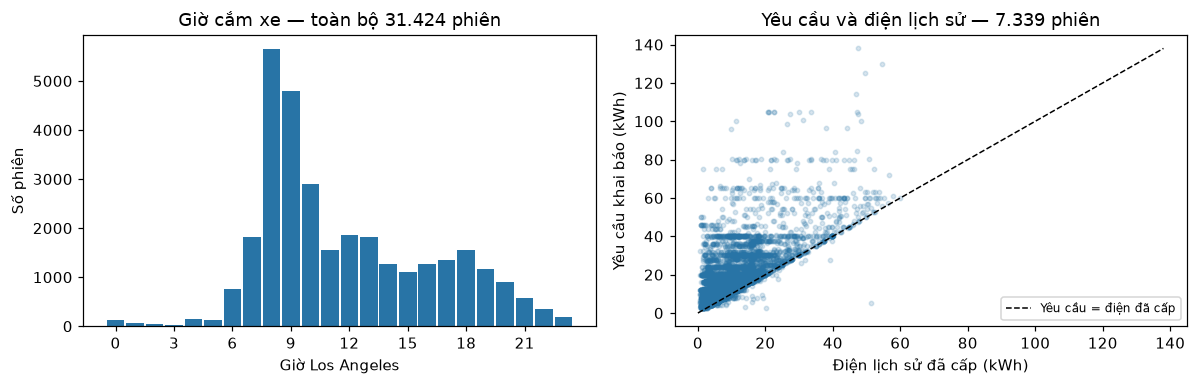

Nhiều điểm trên đường chéo cho thấy yêu cầu cao hơn điện đã nhận; chưa đủ để kết luận người dùng khai sai.


In [24]:
print('Cột nguồn: sessionID, stationID, connectionTime, disconnectTime, userInputs; kWhDelivered chỉ dùng EDA.')
print('Trong userInputs lấy modifiedAt, requestedDeparture, kWhRequested; ts_start_utc chỉ kiểm tra độ phủ.')
print(f"Trong CSV: {thong_tin_file['ts_sessions']:,}/{thong_tin_file['sessions']:,} phiên có chuỗi; mốc cuối {thong_tin_file['ts_latest']} (chỉ đến 5/2019).")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
hours = phien_goc.connectionTime_dt.dt.tz_convert('America/Los_Angeles').dt.hour
axes[0].hist(hours, bins=np.arange(25) - 0.5, color='#2874a6', rwidth=0.9)
axes[0].set(title='Giờ cắm xe — toàn bộ 31.424 phiên',
    xlabel='Giờ Los Angeles',
    ylabel='Số phiên',
    xticks=range(0, 24, 3))
axes[1].scatter(phien_duoc_chon.kWhDelivered, phien_duoc_chon.request, s=8, alpha=0.18, color='#2874a6')
upper = max(phien_duoc_chon.kWhDelivered.max(), phien_duoc_chon.request.max())
axes[1].plot([0, upper], [0, upper], 'k--', lw=1, label='Yêu cầu = điện đã cấp')
axes[1].set(title='Yêu cầu và điện lịch sử — 7.339 phiên',
    xlabel='Điện lịch sử đã cấp (kWh)',
    ylabel='Yêu cầu khai báo (kWh)')
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(THU_MUC_KET_QUA / 'eda.png', bbox_inches='tight')
plt.show()
print('Nhiều điểm trên đường chéo cho thấy yêu cầu cao hơn điện đã nhận; chưa đủ để kết luận người dùng khai sai.')

**Giải thích sau cell:** Trái là GIỜ cắm xe theo Los Angeles, không phải tháng. Điểm trên đường chéo bên phải nghĩa là yêu cầu lớn hơn điện lịch sử đã nhận; chưa chứng minh người dùng khai sai.

### EDA bổ sung về thời lượng và chất lượng dữ liệu
Thời lượng đậu = `disconnectTime - connectionTime`, không phải thời gian xe thực sự nhận dòng.
Hai hình dưới dùng mọi phiên **năm 2019**, gồm cả các phiên ngoài cohort mô phỏng.
Thống kê thiếu khai báo và thiếu chuỗi dùng toàn bộ 31.424 phiên; thiếu một trường phục vụ nghiên cứu
không đồng nghĩa toàn bộ phiên đó sai. Các bất thường chỉ được đếm ở đây, quy trình chọn cohort giữ nguyên.

In [25]:
parking_hours = (phien_goc.disconnectTime_dt - phien_goc.connectionTime_dt).dt.total_seconds() / 3600
sessions_2019 = phien_goc[phien_goc.year == NAM_CHON].copy()
parking_2019 = parking_hours.loc[sessions_2019.index]
valid_parking_2019 = parking_2019[parking_2019 > 0].dropna()
parking_edges = [0, 1, 2, 4, 6, 8, 12, 24, np.inf]
parking_labels = ['0–1', '1–2', '2–4', '4–6', '6–8', '8–12', '12–24', '>24']
parking_counts = pd.cut(valid_parking_2019, parking_edges, right=True).value_counts(sort=False)
weekday_counts = sessions_2019.connectionTime_dt.dt.tz_convert('America/Los_Angeles').dt.dayofweek.value_counts().reindex(range(7),
    fill_value=0)
chat_luong_du_lieu = pd.DataFrame([['Thiếu thời điểm cắm hoặc rút', int((phien_goc.connectionTime_dt.isna() | phien_goc.disconnectTime_dt.isna()).sum()), len(phien_goc)], ['Thời lượng đậu không dương', int((parking_hours <= 0).sum()), len(phien_goc)], ['Không có danh sách userInputs', int(phien_goc.userInputs.map(lambda x: len(json.loads(x)) == 0 if pd.notna(x) else True).sum()), len(phien_goc)], ['Không có khai báo hợp lệ tại first_control', int(phien_goc.kWhRequested.isna().sum()), len(phien_goc)], ['Không có timestamp chuỗi', int((~phien_goc.has_ts_actual).sum()), len(phien_goc)]],
    columns=['Kiểm tra', 'Số phiên', 'Tổng phiên'])
chat_luong_du_lieu['Tỷ lệ (%)'] = 100 * chat_luong_du_lieu['Số phiên'] / chat_luong_du_lieu['Tổng phiên']
hien_bang(chat_luong_du_lieu.round(2), 'B08. Chất lượng dữ liệu gốc', 'D01')

**B08. Chất lượng dữ liệu gốc** — tra: `D01`

,Kiểm tra,Số phiên,Tổng phiên,Tỷ lệ (%)
0,Thiếu thời điểm cắm hoặc rút,0,31424,0.00
1,Thời lượng đậu không dương,0,31424,0.00
2,Không có danh sách userInputs,15036,31424,47.85
3,Không có khai báo hợp lệ tại first_control,15976,31424,50.84
4,Không có timestamp chuỗi,11335,31424,36.07


In [26]:
nhan_xet("Các lỗi/thiếu trong bảng có thể trùng cùng một phiên, không cộng các hàng để ra số phiên bị loại. Bảng phễu mới mô tả thứ tự lọc thực sự.")

**Nhận xét:** Các lỗi/thiếu trong bảng có thể trùng cùng một phiên, không cộng các hàng để ra số phiên bị loại. Bảng phễu mới mô tả thứ tự lọc thực sự.

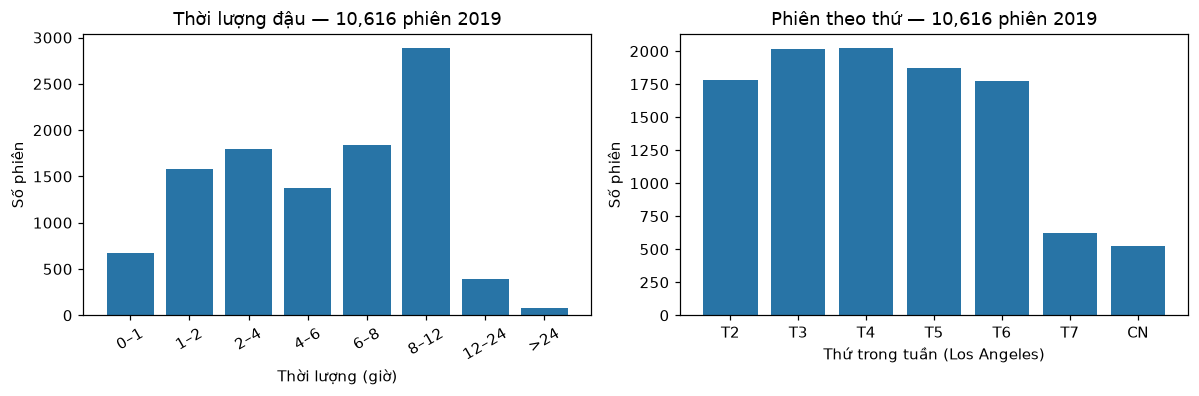

Năm 2019: trung vị thời lượng đậu 5.82 giờ; khoảng tứ phân vị [2.36; 8.58] giờ.
Phiên từ thứ Hai đến thứ Sáu chiếm 89.22%; đây là mô tả file, không phải quy luật cho mọi trạm.


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar(parking_labels, parking_counts.to_numpy(), color='#2874a6')
axes[0].set(title=f'Thời lượng đậu — {len(valid_parking_2019):,} phiên 2019',
    xlabel='Thời lượng (giờ)',
    ylabel='Số phiên')
axes[0].tick_params(axis='x', labelrotation=30)
axes[1].bar(['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN'], weekday_counts, color='#2874a6')
axes[1].set(title=f'Phiên theo thứ — {len(sessions_2019):,} phiên 2019',
    xlabel='Thứ trong tuần (Los Angeles)',
    ylabel='Số phiên')
fig.tight_layout()
fig.savefig(THU_MUC_KET_QUA / 'eda_bo_sung.png', bbox_inches='tight')
plt.show()
eda_info = dict(year=NAM_CHON,
    year_sessions=len(sessions_2019),
    positive_parking_sessions=len(valid_parking_2019),
    parking_median_h=float(valid_parking_2019.median()),
    parking_q1_h=float(valid_parking_2019.quantile(0.25)),
    parking_q3_h=float(valid_parking_2019.quantile(0.75)),
    parking_over24=int((valid_parking_2019 > 24).sum()),
    parking_labels=parking_labels,
    parking_counts=parking_counts.tolist(),
    weekday_counts=weekday_counts.tolist(),
    weekday_share_pct=float(100 * weekday_counts.iloc[:5].sum() / weekday_counts.sum()))
(THU_MUC_KET_QUA / 'eda_bo_sung.json').write_text(json.dumps(eda_info, ensure_ascii=False, indent=2),
    encoding='utf-8')
chat_luong_du_lieu.to_csv(THU_MUC_KET_QUA / 'chat_luong_du_lieu.csv', index=False)
print(f"Năm {NAM_CHON}: trung vị thời lượng đậu {eda_info['parking_median_h']:.2f} giờ; khoảng tứ phân vị [{eda_info['parking_q1_h']:.2f}; {eda_info['parking_q3_h']:.2f}] giờ.")
print(f"Phiên từ thứ Hai đến thứ Sáu chiếm {eda_info['weekday_share_pct']:.2f}%; đây là mô tả file, không phải quy luật cho mọi trạm.")

**Giải thích sau cell:** Thời lượng đậu là giờ rút trừ giờ cắm, khác thời gian thực sự nhận dòng. Bảng thiếu dữ liệu dùng phiên gốc; biểu đồ thời lượng/thứ dùng mọi phiên 2019.

### Luồng xử lý để cả nhóm dễ trình bày
```text
CSV → mỗi phiên lấy khai báo đã có lúc xe đến → chia ngày theo thời gian
    → mô phỏng từng 15 phút → PPO chọn hai nút điều chỉnh
    → bộ phân bổ ra công suất từng xe → bộ bảo vệ giới hạn điện
    → tính điện đã cấp, điện thiếu, chờ/chậm và điểm J
```
Máy biết giờ cắm và khai báo nhờ CSV; biết điện còn cần vì lấy yêu cầu trừ điện vừa cấp. Máy không đo pin thật và không biết trước xe mới nào sẽ đến. Chuỗi dòng điện lịch sử phục vụ khảo sát dữ liệu, không được phát lại như phản ứng của xe với hành động RL mới.

## 3. Môi trường, giới hạn điện và các chỉ số
Mỗi ngày là một episode. Mỗi slot dài 0,25 giờ; cấp p kW làm nhu cầu còn lại giảm 0,25 p kWh. Xe nhận tối đa 6,656 kW và không vượt lượng điện còn cần.

**Phân bổ và bảo vệ hạ tầng:** FIFO/EDF/LLF giữ thứ tự ưu tiên ngay trong từng pod 80 A; Equal chia đều trong giới hạn từng nhóm; bộ phân bổ PPO cũng xét ngân sách từng pod. Sau đó, nếu dòng sơ/thứ cấp còn vượt giới hạn, bộ bảo vệ giảm đồng tỷ lệ đề xuất. Tất cả thuật toán dùng cùng công thức kiểm tra điện. Đây là cách chiếu an toàn đơn giản của nhóm, **chưa phải bộ phân bổ tối ưu**; có thể còn công suất ở cổng khác chưa được dùng.

Tổng tải dưới 150 kW chưa chắc khả thi:8 xe cùng trong một pod có thể muốn 53,248 kW, nhưng pod chỉ cho 16,64 kW. Vì vậy thay 45 thành 150 mà bỏ qua nhóm cổng/pha là chưa đủ.

| Phương pháp | Quy tắc trước bộ bảo vệ |
|---|---|
| FIFO | Xe đến trước được ưu tiên; đến cùng slot phá hòa theo thứ tự dữ liệu cố định |
| EDF | Ưu tiên hạn rời khai báo sớm |
| LLF | Ưu tiên thời gian dự phòng nhỏ nhất |
| Equal | Chia đều, chặn theo lượng điện mỗi xe còn cần |
| AverageRate | Điện còn cần chia thời gian đến hạn |
| Fixed100 | Cùng bộ phân bổ/guard với PPO, nhưng ngân sách tối đa và ưu tiên cố định |

**Nhận xét:** Fixed100 giữ cùng bộ phân bổ nhưng không học, giúp kiểm tra phần học của PPO có thêm ích lợi hay không. LLF là đối chứng mạnh; chưa có lời giải tối ưu để gọi nó tối ưu ở đây.

Ngân sách u của PPO là đề xuất. Guard có thể yêu cầu cấp nhiều hơn u× 150 để bám hạn; bộ bảo vệ điện vẫn áp dụng sau đó, nên không bảo đảm mọi yêu cầu của guard được thực hiện.

| Chỉ số | Cách tính |
|---|---|
| Thiếu kWh / % | Yêu cầu − điện mô phỏng đã cấp; tỷ lệ=100 ×thiếu/yêu cầu |
| Chờ ban đầu phút | Từ slot điều khiển đầu đến slot đầu có p>10⁻⁶ kW; xe không bắt đầu được tính tới lúc dừng phục vụ |
| Chậm tương đương phút | Thời gian tới hoàn thành/dừng − thời gian cấp chính lượng điện đã nhận nếu liên tục ở 6,656 kW |
| Tỷ lệ phân bổ % | 100 ×ΣP / Σ tổng công suất các xe đang cần điện có thể nhận; mẫu số chưa áp giới hạn mạng |
| Dùng trần trạm % | 100 ×ΣP /(150 ×số slot có ít nhất một xe trong cửa sổ phục vụ), kể cả xe đã đủ điện |
| Dòng/giới hạn | Dòng lớn nhất chia mức cho phép; ≤1 là không vượt giới hạn |

**Nhận xét:** PPO nhận thông tin tóm tắt và chọn hai nút điều chỉnh; bộ phân bổ mới quyết định kW từng xe. Không đưa giờ rút thật tương lai hoặc điện cuối phiên vào quan sát.

Tỷ lệ phân bổ nhỏ hơn 100% có thể do giới hạn điện, không tự chứng minh bộ điều khiển lãng phí. Tập xe còn nhu cầu phụ thuộc policy nên chỉ số này không có mẫu số cố định giữa thuật toán. Dùng trần có mẫu số chung theo cửa sổ phục vụ của cùng ngày.

Chờ chỉ tính sau lúc xe đã cắm; không có dữ liệu hàng chờ ngoài trạm. Chậm tương đương không phải thời gian hoàn thành sau deadline. Slot cuối công suất nhỏ có thể tạo vài phút chậm do lưới 15 phút.

### Máy nhìn gì, quyết định gì, học từ đâu?

| Thành phần | Diễn giải dễ hiểu | Nằm ở đâu |
|---|---|---|
| Thông tin đưa vào PPO | 14 số tóm tắt: giờ, số xe, điện còn cần, độ gấp, tải trước đó, chờ ban đầu và áp lực hai pod | `MoiTruongSac.obs()` |
| Quyết định của PPO | Hai số: dùng bao nhiêu ngân sách và ưu tiên mức độ gấp ra sao | `mo_hinh.predict()` → `u`, `alpha` |
| Công suất từng xe | Bộ phân bổ chuyển hai số thành danh sách kW; bộ bảo vệ chặn các giới hạn | `phan_bo_tu_hanh_dong()` và `bao_ve_gioi_han_dien()` |
| Phản hồi để học | Điểm âm khi thiếu điện, chờ/chậm lâu hoặc tập trung tải; ít bị trừ điểm hơn là tốt hơn | `MoiTruongSac.step()` |
| Cách chấm cuối | Chạy trên 83 ngày test, giữ đủ 5 seed, cùng giới hạn cho mọi cách phân bổ | `cham_diem_cac_ngay()` |

**Nhận xét:** PPO nhận thông tin tóm tắt và chọn hai nút điều chỉnh; bộ phân bổ mới quyết định kW từng xe. Không đưa giờ rút thật tương lai hoặc điện cuối phiên vào quan sát.

**Lý do chọn mô hình:** FIFO là mốc đến trước; EDF xét hạn; LLF xét cả hạn và điện cần; Equal/AverageRate là cách chia đơn giản. Fixed100 giữ nguyên bộ phân bổ của PPO nhưng không học: nhờ đó kiểm tra phần mạng học được có đem lại ích lợi. Q-learning là mốc RL dạng bảng; PPO xử lý các đầu vào và hành động liên tục. Đây là lý do thử PPO, không phải bằng chứng nó phải tốt nhất.

LLF là đối chứng mạnh trong bài này; chưa có lời giải tối ưu cùng điều kiện nên không gọi LLF là tối ưu lý thuyết của simulator.

In [28]:
def phan_bo_theo_thu_tu(tran_tung_xe_kw, ngan_sach_kw, thu_tu):
    """Cấp theo thứ tự cho tới khi hết ngân sách. Xe cuối có thể chỉ nhận một phần."""
    cong_suat_kw = np.zeros_like(tran_tung_xe_kw)
    tran_theo_thu_tu = tran_tung_xe_kw[thu_tu]
    cong_suat_kw[thu_tu] = np.clip(ngan_sach_kw - (np.cumsum(tran_theo_thu_tu) - tran_theo_thu_tu),
        0,
        tran_theo_thu_tu)
    return cong_suat_kw

def chia_deu_cong_suat(tran_tung_xe_kw, ngan_sach_kw):
    """Tìm mức chia đều; xe cần ít hơn được nhận vừa đủ, không cấp thừa."""
    if tran_tung_xe_kw.sum() <= ngan_sach_kw:
        return tran_tung_xe_kw.copy()
    muc_duoi, muc_tren = (0.0, float(tran_tung_xe_kw.max()))
    for _ in range(35):
        muc_thu = (muc_duoi + muc_tren) / 2
        if np.minimum(tran_tung_xe_kw, muc_thu).sum() > ngan_sach_kw:
            muc_tren = muc_thu
        else:
            muc_duoi = muc_thu
    return np.minimum(tran_tung_xe_kw, muc_duoi)

def phan_bo_tu_hanh_dong(dien_con_lai_kwh,
    gio_con_lai,
    tran_tung_xe_kw,
    ngan_sach_kw,
    ty_le_ngan_sach,
    muc_uu_tien,
    use_safety=True,
    nhom_pod=None):
    """Hai nút u/alpha → công suất từng xe: phần phải cấp gấp + phần bổ sung theo ưu tiên."""
    bat_buoc_kw = np.clip((dien_con_lai_kwh - np.maximum(gio_con_lai - BUOC_GIO, 0) * CONG_SUAT_XE_KW) / BUOC_GIO,
        0,
        tran_tung_xe_kw) if use_safety else np.zeros_like(tran_tung_xe_kw)
    if nhom_pod is not None:
        for xe_trong_pod in nhom_pod:
            da_dung = bat_buoc_kw[xe_trong_pod].sum()
            tran_pod_kw = DIEN_AP_V * 80 / 1000
            if da_dung > tran_pod_kw:
                bat_buoc_kw[xe_trong_pod] *= tran_pod_kw / da_dung
    if bat_buoc_kw.sum() >= ngan_sach_kw:
        return bat_buoc_kw * ngan_sach_kw / bat_buoc_kw.sum()
    ngan_sach_them_kw = max(0,
        min(ty_le_ngan_sach * ngan_sach_kw - bat_buoc_kw.sum(), ngan_sach_kw - bat_buoc_kw.sum()))
    diem_uu_tien = muc_uu_tien / np.maximum(gio_con_lai - dien_con_lai_kwh / CONG_SUAT_XE_KW,
        0.01) + (1 - muc_uu_tien) * dien_con_lai_kwh / 30
    return bat_buoc_kw + phan_bo_uu_tien_theo_pod(tran_tung_xe_kw - bat_buoc_kw,
        ngan_sach_them_kw,
        np.argsort(-diem_uu_tien, kind='stable'),
        nhom_pod,
        None if nhom_pod is None else DIEN_AP_V * 80 / 1000 - nhom_pod @ bat_buoc_kw)

In [29]:
class MoiTruongSac(gym.Env):
    """Một ngày sạc. reset() mở ngày; obs() tóm tắt; step() cấp điện; result() chốt sổ."""
    metadata = {"render_modes": []}

    def __init__(self, days, p_limit=TRAN_TRAM_KW, use_safety=True, hardware=True):
        super().__init__()
        self.cac_ngay = days
        self.tran_kw = p_limit
        self.bat_uu_tien_gap = use_safety
        self.bat_gioi_han_dien = hardware
        self.action_space = spaces.Box(-1.0, 1.0, (2,), dtype=np.float32)
        self.observation_space = spaces.Box(-np.inf, np.inf, (14,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        """Mở một ngày; chỉ số day_idx giúp chấm đúng cùng ngày cho mọi phương pháp."""
        super().reset(seed=seed)
        if options and "day_idx" in options:
            chi_so_ngay = options["day_idx"]
        else:
            chi_so_ngay = int(self.np_random.integers(len(self.cac_ngay)))

        self.ngay = self.cac_ngay[chi_so_ngay]
        self.dien_con_lai = self.ngay["req"].copy()
        self.buoc = 0
        self.tai_buoc_truoc_kw = 0.0
        self.tai_kw = np.zeros(self.ngay["T"])
        self.thieu_luc_roi_kwh = 0.0
        self.so_buoc_uu_tien_gap = 0
        self.so_quyet_dinh = 0
        self.da_nhan_dien = np.zeros(self.ngay["n"], dtype=bool)
        self.cho_phut = np.zeros(self.ngay["n"])
        self.cham_phut = np.zeros(self.ngay["n"])
        self.tong_kha_nang_kw_buoc = 0.0
        self.tong_reward = 0.0
        self.ty_so_dong_lon_nhat = np.zeros(8)
        self.so_buoc_bi_chieu_giam = 0
        self.so_buoc_co_xe_can_dien = 0
        self.kwh_de_xuat_bi_giam = 0.0
        return self.obs(), {}

    def active(self):
        """Xe đã đến, chưa dừng phục vụ, và còn thiếu điện. Không nhìn xe tương lai."""
        da_den = self.ngay["arr"] <= self.buoc
        chua_dung = self.ngay["stop"] > self.buoc
        con_can_dien = self.dien_con_lai > 1e-8
        return np.where(da_den & chua_dung & con_can_dien)[0]

    def obs(self):
        """14 số đúng thứ tự model đã học. Các mẫu số 20/150/4/8 là chuẩn hóa."""
        quan_sat = np.zeros(14, dtype=np.float32)
        if self.buoc >= self.ngay["T"]:
            return quan_sat

        gio = self.ngay["hours"][self.buoc]
        quan_sat[:2] = [np.sin(2 * np.pi * gio / 24), np.cos(2 * np.pi * gio / 24)]
        xe = self.active()
        if len(xe):
            dien_can_kwh = self.dien_con_lai[xe]
            gio_con_lai = (self.ngay["promise"][xe] - self.buoc) * BUOC_GIO
            du_phong_gio = gio_con_lai - dien_can_kwh / CONG_SUAT_XE_KW
            tran_tung_xe_kw = np.minimum(CONG_SUAT_XE_KW, dien_can_kwh / BUOC_GIO)
            bat_buoc_kw = np.clip(
                (dien_can_kwh - np.maximum(gio_con_lai - BUOC_GIO, 0) * CONG_SUAT_XE_KW) / BUOC_GIO,
                0, tran_tung_xe_kw,
            )
            quan_sat[2:9] = [
                len(xe) / 20,
                dien_can_kwh.sum() / 150,
                min(bat_buoc_kw.sum() / self.tran_kw, 10),
                np.clip(du_phong_gio.min() / 4, -20, 20),
                np.clip(du_phong_gio.mean() / 4, -20, 20),
                gio_con_lai.mean() / 8,
                np.minimum(CONG_SUAT_XE_KW, dien_can_kwh / gio_con_lai).sum() / self.tran_kw,
            ]
        quan_sat[9] = self.tai_buoc_truoc_kw / self.tran_kw
        xe_chua_bat_dau = xe[~self.da_nhan_dien[xe]]
        if len(xe_chua_bat_dau):
            da_cho_gio = (self.buoc - self.ngay["arr"][xe_chua_bat_dau]) * BUOC_GIO
            quan_sat[10:12] = [da_cho_gio.mean() / 4, da_cho_gio.max() / 4]
        if self.bat_gioi_han_dien and len(xe):
            tran_tung_xe_kw = np.minimum(CONG_SUAT_XE_KW, self.dien_con_lai[xe] / BUOC_GIO)
            quan_sat[12:14] = self.ngay["pods"][:, xe] @ tran_tung_xe_kw / TRAN_POD_KW
        return quan_sat

    def step(self, action, rule=None):
        """Một bước: chọn xe → chia kW → giữ giới hạn → cộng điện/thời gian → reward."""
        if self.buoc >= self.ngay["T"]:
            raise RuntimeError("Ngày đã kết thúc; gọi reset() trước khi step().")
        xe = self.active()
        cong_suat_kw = np.zeros(len(xe))
        dien_can_kwh = self.dien_con_lai[xe]
        tong_cho_buoc = 0.0
        tong_cham_buoc = 0.0

        if len(xe):
            tran_tung_xe_kw = np.minimum(CONG_SUAT_XE_KW, dien_can_kwh / BUOC_GIO)
            gio_con_lai = (self.ngay["promise"][xe] - self.buoc) * BUOC_GIO
            nhom_pod = self.ngay["pods"][:, xe] if self.bat_gioi_han_dien else None
            if rule == "ASAP":
                cong_suat_kw = tran_tung_xe_kw
            elif rule == "Equal":
                cong_suat_kw = chia_deu_cong_suat(tran_tung_xe_kw, self.tran_kw)
                if nhom_pod is not None:
                    for mat_na in nhom_pod:
                        cong_suat_kw[mat_na] = chia_deu_cong_suat(cong_suat_kw[mat_na], TRAN_POD_KW)
            elif rule in ["FIFO", "EDF", "LLF"]:
                if rule == "FIFO":
                    tieu_chi_uu_tien = self.ngay["arr"][xe]
                elif rule == "EDF":
                    tieu_chi_uu_tien = gio_con_lai
                else:
                    tieu_chi_uu_tien = gio_con_lai - dien_can_kwh / CONG_SUAT_XE_KW
                thu_tu = np.argsort(tieu_chi_uu_tien, kind="stable")
                cong_suat_kw = phan_bo_uu_tien_theo_pod(
                    tran_tung_xe_kw, self.tran_kw, thu_tu, nhom_pod,
                )
            elif rule == "AverageRate":
                cong_suat_kw = np.minimum(tran_tung_xe_kw, dien_can_kwh / gio_con_lai)
                if cong_suat_kw.sum() > self.tran_kw:
                    cong_suat_kw *= self.tran_kw / cong_suat_kw.sum()
            else:
                # Model trả [-1,1]; đổi sang [0,1] cho hai nút ngân sách/ưu tiên.
                ty_le_ngan_sach, muc_uu_tien = (np.clip(np.asarray(action), -1, 1) + 1) / 2
                cong_suat_kw = phan_bo_tu_hanh_dong(
                    dien_can_kwh, gio_con_lai, tran_tung_xe_kw, self.tran_kw,
                    ty_le_ngan_sach, muc_uu_tien, self.bat_uu_tien_gap, nhom_pod,
                )
                self.so_quyet_dinh += 1
                if cong_suat_kw.sum() > ty_le_ngan_sach * self.tran_kw + 1e-6:
                    self.so_buoc_uu_tien_gap += 1

            if self.bat_gioi_han_dien:
                de_xuat_kw = cong_suat_kw.copy()
                cong_suat_kw = bao_ve_gioi_han_dien(
                    cong_suat_kw, self.ngay["matrix"][:, xe], self.ngay["pods"][:, xe],
                )
                ty_so_dong = np.abs(self.ngay["matrix"][:, xe] @ cong_suat_kw) / DONG_GIOI_HAN_A
                assert ty_so_dong.max() <= 1 + 1e-7, "Vượt dòng giới hạn hạ tầng"
                self.ty_so_dong_lon_nhat = np.maximum(self.ty_so_dong_lon_nhat, ty_so_dong)
                self.so_buoc_bi_chieu_giam += int(np.any(de_xuat_kw - cong_suat_kw > 1e-7))
                self.kwh_de_xuat_bi_giam += float(tinh_dien_da_cap((de_xuat_kw - cong_suat_kw).sum()))

            self.so_buoc_co_xe_can_dien += 1
            assert np.all(cong_suat_kw >= -1e-7)
            assert np.all(cong_suat_kw <= tran_tung_xe_kw + 1e-7)
            if rule != "ASAP":
                assert cong_suat_kw.sum() <= self.tran_kw + 1e-6

            self.tong_kha_nang_kw_buoc += float(tran_tung_xe_kw.sum())
            self.da_nhan_dien[xe[cong_suat_kw > 1e-6]] = True
            cho_buoc, cham_buoc = tinh_cho_cham_buoc(self.da_nhan_dien[xe], cong_suat_kw)
            self.cho_phut[xe] += cho_buoc
            self.cham_phut[xe] += cham_buoc
            tong_cho_buoc = float(cho_buoc.sum())
            tong_cham_buoc = float(cham_buoc.sum())
            self.dien_con_lai[xe] = np.maximum(dien_can_kwh - tinh_dien_da_cap(cong_suat_kw), 0)

        tong_tai_kw = float(cong_suat_kw.sum())
        self.tai_kw[self.buoc] = tong_tai_kw
        xe_roi_buoc_nay = self.ngay["stop"] == self.buoc + 1
        dien_thieu_luc_roi = float(self.dien_con_lai[xe_roi_buoc_nay].sum())
        self.thieu_luc_roi_kwh += dien_thieu_luc_roi
        reward = tinh_reward_buoc(
            dien_thieu_luc_roi, self.ngay["req"].sum(), tong_cho_buoc, tong_cham_buoc,
            self.ngay["n"], tong_tai_kw, self.tran_kw, self.ngay["T"],
        )
        self.tong_reward += reward
        self.tai_buoc_truoc_kw = tong_tai_kw
        self.buoc += 1
        da_het_ngay = self.buoc >= self.ngay["T"]
        return self.obs(), reward, da_het_ngay, False, {}

    def result(self):
        """Sổ chi tiết cuối ngày. Các khóa trả về giữ trùng CSV của lần huấn luyện đã có."""
        yeu_cau_kwh = self.ngay["req"].sum()
        da_cap_kwh = yeu_cau_kwh - self.dien_con_lai.sum()
        assert abs(tinh_dien_da_cap(self.tai_kw.sum()) - da_cap_kwh) < 1e-6
        assert abs(self.thieu_luc_roi_kwh - self.dien_con_lai.sum()) < 1e-6
        cac_buoc = np.arange(self.ngay["T"])
        co_xe_trong_cua_so = np.any(
            (self.ngay["arr"][:, None] <= cac_buoc) & (self.ngay["stop"][:, None] > cac_buoc), axis=0,
        )
        return dict(
            network_peak_ratio=float(self.ty_so_dong_lon_nhat.max()),
            pod_peak_ratio=float(self.ty_so_dong_lon_nhat[:2].max()),
            phase_peak_ratio=float(self.ty_so_dong_lon_nhat[2:].max()),
            network_clip_pct=100 * self.so_buoc_bi_chieu_giam / max(1, self.so_buoc_co_xe_can_dien),
            clipped_kwh=self.kwh_de_xuat_bi_giam,
            n=self.ngay["n"], wait_min=self.cho_phut.copy(), delay_min=self.cham_phut.copy(),
            never_started_pct=100 * float((~self.da_nhan_dien).mean()),
            allocation_pct=100 * self.tai_kw.sum() / max(self.tong_kha_nang_kw_buoc, 1e-12),
            station_utilization_pct=100 * self.tai_kw.sum() / max(self.tran_kw * co_xe_trong_cua_so.sum(), 1e-12),
            reward_sum=self.tong_reward, date=self.ngay["date"], P=self.tai_kw.copy(),
            req=yeu_cau_kwh, rem=self.dien_con_lai.copy(), delivered=da_cap_kwh,
            fulfilled_fraction=float((self.dien_con_lai <= 0.01).mean()),
            individual_unavoidable=float(tinh_can_thieu_rieng_xe(self.ngay["req"], self.ngay["arr"], self.ngay["stop"]).sum()),
            guard_binding_pct=100 * self.so_buoc_uu_tien_gap / max(self.so_quyet_dinh, 1),
        )


def tinh_chi_so(ket_qua, limit=TRAN_TRAM_KW):
    """F01–F18: một hàng chỉ số cho một ngày và một seed. Tra SO_CONG_THUC theo khóa."""
    tai_kw = ket_qua["P"]
    thieu_kwh = ket_qua["req"] - ket_qua["delivered"]
    cho_trung_binh = float(ket_qua["wait_min"].mean())
    cham_trung_binh = float(ket_qua["delay_min"].mean())
    tai_binh_phuong_chuan = float(np.mean((tai_kw / limit) ** 2))
    thanh_phan_J = tinh_thanh_phan_J(
        thieu_kwh / ket_qua["req"], cho_trung_binh, cham_trung_binh, tai_binh_phuong_chuan,
    )
    diem_J = sum(thanh_phan_J.values())
    assert abs(diem_J + ket_qua["reward_sum"]) < 1e-6, "Tổng reward ngày phải bằng -J"
    return dict(
        network_peak_ratio=ket_qua["network_peak_ratio"],
        pod_peak_ratio=ket_qua["pod_peak_ratio"], phase_peak_ratio=ket_qua["phase_peak_ratio"],
        network_clip_pct=ket_qua["network_clip_pct"], clipped_kwh=ket_qua["clipped_kwh"],
        date=ket_qua["date"], sessions=ket_qua["n"], requested_kwh=ket_qua["req"],
        delivered_kwh=ket_qua["delivered"], unmet_kwh=thieu_kwh,
        unmet_pct=100 * thieu_kwh / ket_qua["req"],
        energy_service_pct=100 * ket_qua["delivered"] / ket_qua["req"],
        session_service_pct=100 * ket_qua["fulfilled_fraction"],
        wait_min=cho_trung_binh, delay_min=cham_trung_binh,
        never_started_pct=ket_qua["never_started_pct"], allocation_pct=ket_qua["allocation_pct"],
        station_utilization_pct=ket_qua["station_utilization_pct"],
        peak_kw=tai_kw.max(), smooth_kW2h=float((tai_kw * tai_kw).sum() * BUOC_GIO),
        smooth_normalized=tai_binh_phuong_chuan,
        overload_kwh=float(np.maximum(tai_kw - limit, 0).sum() * BUOC_GIO),
        individual_unavoidable_kwh=ket_qua["individual_unavoidable"],
        guard_binding_pct=ket_qua["guard_binding_pct"], objective=diem_J,
    )

In [30]:
class MoiTruongValidation(MoiTruongSac):

    def reset(self, seed=None, options=None):
        self.k = getattr(self, 'k', -1) + 1
        return super().reset(seed=seed, options={'day_idx': self.k % len(self.cac_ngay)})

def mo_phong_cac_ngay(days, policy=None, rule=None, limit=TRAN_TRAM_KW, use_safety=True, hardware=True):
    """Chạy từng ngày từ reset tới hết; trả sổ chi tiết ngày, chưa lấy trung bình các ngày."""
    moi_truong = MoiTruongSac(days, limit, use_safety, hardware)
    cac_ket_qua = []
    for chi_so_ngay in range(len(days)):
        quan_sat, _ = moi_truong.reset(options={'day_idx': chi_so_ngay})
        ket_thuc = False
        while not ket_thuc:
            hanh_dong = policy(quan_sat) if policy else np.zeros(2)
            quan_sat, _, ket_thuc, _, _ = moi_truong.step(hanh_dong, rule)
        cac_ket_qua.append(moi_truong.result())
    return cac_ket_qua

def cham_diem_cac_ngay(days, policy=None, rule=None, **kwargs):
    """Đổi mỗi sổ ngày thành một hàng chỉ số bằng tinh_chi_so()."""
    return pd.DataFrame([tinh_chi_so(so_ngay, kwargs.get('limit', TRAN_TRAM_KW)) for so_ngay in mo_phong_cac_ngay(days, policy, rule, **kwargs)])

**Giải thích sau cell:** Từ công suất vừa cấp, máy cập nhật điện còn thiếu và số phút chờ/chậm. Dòng các pha được tính theo cách nối Caltech, kiểm tra ở từng slot. Cuối ngày kiểm tra bảo toàn điện và tổng reward=−J.

### Chờ, chậm và thiếu điện khác nhau thế nào?
- **Chờ ban đầu:** xe vào mốc điều khiển 9:00, đến 9:15 mới được cấp điện → chờ 15 phút. Xe chưa được cấp lần nào tính đến lúc dừng phục vụ.
- **Chậm tương đương:** xe cần 3,328 kWh; ở 6,656 kW cần đúng 30 phút. Nếu từ lúc đến tới lúc đủ điện mất 45 phút, chậm tương đương là 45 − 30 = 15 phút, dù cuối cùng xe đủ điện.
- Xe nhận công suất tối đa suốt 30 phút nhưng yêu cầu 10 kWh vẫn thiếu 6,672 kWh và có thể chậm tương đương bằng 0. Vì vậy **chậm trong bài này không phải thời gian sạc thêm lượng điện thiếu**, cũng không phải số phút trễ sau giờ hẹn. Không ghép số delay của hai bài 45 kW với bản này.

Mốc giờ được làm tròn theo 15 phút; đây là số trong mô phỏng. Tổng chậm đã bao gồm chờ ban đầu; J còn phạt riêng chờ để ưu tiên bắt đầu phục vụ. Khi đọc kết quả phải đọc cùng điện thiếu.

In [31]:
def toy(ports, req=None, T=4):
    n = len(ports)
    matrix, pods = tao_ma_tran_gioi_han(ports)
    return dict(date='toy',
        T=T,
        n=n,
        arr=np.zeros(n, int),
        stop=np.full(n, T),
        promise=np.full(n, T),
        req=np.full(n, 20.0) if req is None else np.asarray(req, float),
        hours=np.arange(T) * 0.25,
        ids=np.arange(n).astype(str),
        station=np.arange(n).astype(str),
        space=np.array(ports),
        matrix=matrix,
        pods=pods)
assert abs(CONG_SUAT_XE_KW - 6.656) < 1e-12 and TRAN_TRAM_KW == 150
ports = sorted(POD_CC)
matrix, pods = tao_ma_tran_gioi_han(ports)
proposed = np.full(8, CONG_SUAT_XE_KW)
safe = bao_ve_gioi_han_dien(proposed, matrix, pods)
assert np.isclose(safe.sum(), 16.64) and np.isclose(safe.max(), 2.08)
assert np.abs(matrix @ proposed)[0] > 80 and np.abs(matrix @ safe)[0] <= 80 + 1e-08
matrix, pods = tao_ma_tran_gioi_han(['CA-308', 'CA-304', 'CA-307'])
v = np.abs(matrix @ np.full(3, CONG_SUAT_XE_KW))
assert np.allclose(v[2:5], np.sqrt(3) * 32) and np.allclose(v[5:], 24)
assert proposed.sum() < 150
ab = sorted(CONG_THEO_PHA['BC'])
matrix, pods = tao_ma_tran_gioi_han(ab)
v = np.full(len(ab), CONG_SUAT_XE_KW)
assert np.max(np.abs(matrix @ v) / DONG_GIOI_HAN_A) > 1
assert np.max(np.abs(matrix @ bao_ve_gioi_han_dien(v, matrix, pods)) / DONG_GIOI_HAN_A) <= 1 + 1e-08
try:
    tao_ma_tran_gioi_han(['unknown'])
except ValueError:
    pass
else:
    raise AssertionError('Unknown port accepted')
d = toy(['CA-308'], [1.664], T=1)
r = mo_phong_cac_ngay([d], rule='FIFO')[0]
m = tinh_chi_so(r)
assert abs(m['unmet_kwh']) < 1e-08 and abs(m['wait_min']) < 1e-08 and (abs(m['delay_min']) < 1e-08)
d = toy(sorted(POD_CC)[:4] + ['CA-308'], T=1)
fifo = mo_phong_cac_ngay([d], rule='FIFO')[0]
equal = mo_phong_cac_ngay([d], rule='Equal')[0]
assert np.allclose(d['req'][:4] - fifo['rem'][:4], [1.664, 1.664, 0.832, 0])
assert np.allclose(d['req'][:4] - equal['rem'][:4], [1.04] * 4)
assert fifo['wait_min'][3] == 15 and equal['wait_min'].max() == 0
check_env(MoiTruongSac([d]), warn=True)

**Giải thích sau cell:** Các ca tính tay kiểm tra pod 80 A, tải lệch pha, một xe sạc đủ trong 15 phút, mã cổng không hợp lệ và API môi trường. Những kiểm tra này không chọn mo_hinh bằng test.

In [32]:
cac_kich_ban = []
cong_suat_xe_ban_dau = CONG_SUAT_XE_KW
for ten_kich_ban, tran_kich_ban, cong_suat_xe_kich_ban, ap_gioi_han_dien in [('45 kW bản cũ — chỉ trần tổng', 45.0, 6.6, False),
    ('150 kW — chỉ trần tổng', 150.0, 6.656, False),
    ('150 kW — pod và pha Caltech', 150.0, 6.656, True)]:
    CONG_SUAT_XE_KW = cong_suat_xe_kich_ban
    for quy_tac in ['FIFO', 'EDF', 'LLF', 'Equal']:
        bang_cham = cham_diem_cac_ngay(cac_tap['val'],
            rule=quy_tac,
            limit=tran_kich_ban,
            hardware=ap_gioi_han_dien)
        cac_kich_ban.append(dict(scenario=ten_kich_ban, policy=quy_tac, unmet_pct=bang_cham.unmet_pct.mean(), wait_min=bang_cham.wait_min.mean(), delay_min=bang_cham.delay_min.mean(), network_clip_pct=bang_cham.network_clip_pct.mean()))
CONG_SUAT_XE_KW = cong_suat_xe_ban_dau
so_sanh_ha_tang = pd.DataFrame(cac_kich_ban)
hien_bang(so_sanh_ha_tang.round(3), 'B09. Đối chiếu hạ tầng trên validation', 'F03, F04, F05')

**B09. Đối chiếu hạ tầng trên validation** — tra: `F03, F04, F05`

,Cấu hình hạ tầng,Phương pháp,Thiếu (% nhu cầu ngày),Chờ ban đầu (phút),Chậm tương đương (phút),Bước bị chiếu giảm (%)
0,45 kW bản cũ — chỉ trần tổng,FIFO,30.846,25.047,31.481,0.0
1,45 kW bản cũ — chỉ trần tổng,EDF,28.441,17.248,37.611,0.0
2,45 kW bản cũ — chỉ trần tổng,LLF,26.257,20.043,53.666,0.0
3,45 kW bản cũ — chỉ trần tổng,Equal,30.915,0.000,38.598,0.0
4,150 kW — chỉ trần tổng,FIFO,23.028,0.000,5.476,0.0
5,150 kW — chỉ trần tổng,EDF,23.028,0.000,5.476,0.0
6,150 kW — chỉ trần tổng,LLF,23.028,0.000,5.476,0.0
7,150 kW — chỉ trần tổng,Equal,23.028,0.000,5.476,0.0
8,150 kW — pod và pha Caltech,FIFO,25.348,3.884,13.450,0.0
9,150 kW — pod và pha Caltech,EDF,24.669,2.049,13.360,0.0


In [33]:
nhan_xet("Đây là kết quả validation của các quy tắc, không phải test hoặc mức cải thiện riêng của PPO. So sánh cho thấy phải xét pod/pha chứ không chỉ đổi 45 thành 150.")

**Nhận xét:** Đây là kết quả validation của các quy tắc, không phải test hoặc mức cải thiện riêng của PPO. So sánh cho thấy phải xét pod/pha chứ không chỉ đổi 45 thành 150.

In [34]:
so_sanh_ha_tang.to_csv(THU_MUC_KET_QUA / 'doi_chieu_cau_hinh_validation.csv', index=False)

## 4. Reward, Q-learning, PPO và tinh chỉnh
**Q-learning:**9 hành động =3 mức ngân sách {25%,50%,100%} × 3 mức ưu tiên {0;0,5;1}. Không phải chọn 1 trong 9 xe. Bảng Q dùng 4 nhóm thông tin thô: giờ, số xe, điện còn cần và độ khẩn cấp.

**PPO:** chọn hai số ngân sách/ưu tiên liên tục. Quan sát **14 số**:10 số cũ về giờ/xe/điện/hạn/tải;2 số chờ ban đầu;2 số nhu cầu công suất của CC Pod và AV Pod so với giới hạn từng pod. Không cho policy biết xe đến trong tương lai hoặc giờ rút thực trước khi xảy ra. Thông tin gộp vẫn làm mất chi tiết và không bảo đảm biểu diễn Markov đầy đủ.

$$J=4\frac{U}{E}+0,5\frac{\bar W}{60}+0,5\frac{\bar D}{60}+0,1\frac1T\sum_t(P_t/150)^2.$$

U/E là thiếu/yêu cầu của ngày; W,D là phút trung bình trên tất cả phiên. Reward âm các phần phạt phát sinh, tổng ngày bằng−J. Trọng số là ưu tiên thiết kế đã đặt trước khi chấm test, không phải giá tiền hay công thức tối ưu từ bài báo. Giảm 1 điểm phần trăm thiếu làm J giảm 0,04, tương đương 4,8 phút chờ nếu các phần khác giữ nguyên. W đã nằm trong D và còn được phạt riêng để ưu tiên bắt đầu phục vụ; tập trung tải là mục tiêu phụ. Mẫu số E và số phiên cả ngày chỉ để chấm kịch bản offline, không nằm trong quan sát.

**Chạy lại thật trong môi trường mới:**3 duong_hoc rate {0,0001;0,0003;0,001} × 2 mạng {64 × 64;128 × 128} × 2 seed tuning {17,29}, mỗi lượt 300.000 bước yêu cầu. Chọn checkpoint và cấu hình bằng 38 ngày validation. Sau đó học lại từ đầu seed 42–46, không loại seed xấu. Q-learning học 4.000 episode × 5 seed. Giữ mo_phong_cac_ngay 1024, batch 256,10 epoch, gamma 1, GAE 0,95. PPO thực chạy 300.032 bước do hoàn tất mo_phong_cac_ngay. Đây là lưới nhỏ, chưa phải tối ưu toàn cục.

Kết quả cũ 45 kW không được trộn vào bảng chính 150 kW. Nếu so trước–sau thì phải nêu cả việc thay hạ tầng và mức 6,6→6,656, không quy mọi thay đổi cho PPO.

In [35]:
HANH_DONG_Q = [np.array([2 * u - 1, 2 * a - 1], np.float32) for u in [0.25, 0.5, 1.0] for a in [0.0, 0.5, 1.0]]

def nen_trang_thai_Q(quan_sat):
    """Nén quan sát thành 4 nhóm thô để tra bảng Q; không phải toàn bộ 14 số PPO."""
    phan_ngay = np.arctan2(quan_sat[0], quan_sat[1]) % (2 * np.pi) / (2 * np.pi)
    return (int(phan_ngay * 6) % 6,
        min(int(quan_sat[2] * 4), 5),
        min(int(quan_sat[3] * 4), 5),
        int(np.digitize(quan_sat[5], [-0.25, 0, 0.25, 1.0])))

def nap_hoac_hoc_PPO(cau_hinh, seed, phase='tuning', steps=SO_BUOC_PPO):
    """Nạp lượt PPO đã xong; chỉ được học khi bật chế độ. Chọn checkpoint bằng validation."""
    thu_muc = THU_MUC_MODEL / phase / cau_hinh['name'] / f'seed{seed}'
    thu_muc.mkdir(parents=True, exist_ok=True)
    tep_hoan_thanh = thu_muc / 'completed.json'
    if tep_hoan_thanh.exists() and (not HUAN_LUYEN_LAI):
        if not (thu_muc / 'best_model.zip').is_file() or not (thu_muc / 'evaluations.npz').is_file():
            raise FileNotFoundError(f'Model/log PPO chưa đầy đủ: {thu_muc}')
        return json.loads(tep_hoan_thanh.read_text())
    if not CHO_PHEP_HUAN_LUYEN:
        raise FileNotFoundError(f'Thiếu lượt PPO {thu_muc}; bổ sung model hoặc đặt CHE_DO thành HOC_PHAN_THIEU hoặc HOC_LAI.')
    bat_dau = time.time()
    moi_truong = Monitor(MoiTruongSac(cac_tap['train']))
    moi_truong_val = Monitor(MoiTruongValidation(cac_tap['val']))
    ham_cham_val = EvalCallback(moi_truong_val,
        n_eval_episodes=len(cac_tap['val']),
        eval_freq=10240,
        deterministic=True,
        best_model_save_path=str(thu_muc),
        log_path=str(thu_muc),
        verbose=0)
    mo_hinh = PPO('MlpPolicy',
        moi_truong,
        learning_rate=cau_hinh['lr'],
        n_steps=1024,
        batch_size=256,
        n_epochs=10,
        gamma=1.0,
        gae_lambda=0.95,
        policy_kwargs=dict(net_arch=[cau_hinh['width']] * 2),
        seed=seed,
        verbose=0,
        device='cpu')
    mo_hinh.learn(total_timesteps=steps, callback=ham_cham_val)
    if not (thu_muc / 'best_model.zip').exists():
        mo_hinh.save(thu_muc / 'best_model.zip')
    mo_hinh.save(thu_muc / 'last_model.zip')
    model_tot_nhat = PPO.load(thu_muc / 'best_model.zip', device='cpu')
    bang_val = cham_diem_cac_ngay(cac_tap['val'],
        lambda o: model_tot_nhat.predict(o, deterministic=True)[0])
    thong_tin_luot = dict(**cau_hinh,
        seed=seed,
        phase=phase,
        steps=mo_hinh.num_timesteps,
        seconds=time.time() - bat_dau,
        val_objective=float(bang_val.objective.mean()),
        val_wait=float(bang_val.wait_min.mean()),
        val_unmet_pct=float(bang_val.unmet_pct.mean()),
        folder=str(thu_muc))
    bang_val.to_csv(thu_muc / 'validation.csv', index=False)
    tep_hoan_thanh.write_text(json.dumps(thong_tin_luot, indent=2), encoding='utf-8')
    moi_truong.close()
    moi_truong_val.close()
    return thong_tin_luot

def nap_hoac_hoc_Q(seed):
    """Q02: học bảng Q; đánh giá mỗi 200 episode, lưu bảng có J validation tốt nhất."""
    thu_muc = THU_MUC_MODEL / 'q_new' / f'seed{seed}'
    thu_muc.mkdir(parents=True, exist_ok=True)
    tep_hoan_thanh = thu_muc / 'completed.json'
    if tep_hoan_thanh.exists() and (not HUAN_LUYEN_LAI):
        if not (thu_muc / 'best_model.npz').is_file() or not (thu_muc / 'learning.csv').is_file():
            raise FileNotFoundError(f'Model/log Q-learning chưa đầy đủ: {thu_muc}')
        return json.loads(tep_hoan_thanh.read_text())
    if not CHO_PHEP_HUAN_LUYEN:
        raise FileNotFoundError(f'Thiếu lượt Q-learning {thu_muc}; bổ sung model hoặc đặt CHE_DO thành HOC_PHAN_THIEU hoặc HOC_LAI.')
    bat_dau = time.time()
    bo_ngau_nhien = np.random.default_rng(seed)
    bang_Q = defaultdict(lambda: np.zeros(9))
    moi_truong = MoiTruongSac(cac_tap['train'])
    nhat_ky = []
    bang_Q_tot_nhat = None
    J_val_tot_nhat = np.inf

    def policy(quan_sat):
        return HANH_DONG_Q[int(np.argmax(bang_Q.get(nen_trang_thai_Q(quan_sat), np.zeros(9))))]
    for episode in range(SO_EPISODE_Q):
        quan_sat, _ = moi_truong.reset(seed=seed + episode)
        ket_thuc = False
        xac_suat_thu = max(0.05, 1 - episode / (SO_EPISODE_Q * 0.85))
        while not ket_thuc:
            trang_thai = nen_trang_thai_Q(quan_sat)
            chi_so_hanh_dong = int(bo_ngau_nhien.integers(9)) if bo_ngau_nhien.random() < xac_suat_thu else int(np.argmax(bang_Q[trang_thai]))
            quan_sat_sau, reward, ket_thuc, _, _ = moi_truong.step(HANH_DONG_Q[chi_so_hanh_dong])
            trang_thai_sau = nen_trang_thai_Q(quan_sat_sau)
            bang_Q[trang_thai][chi_so_hanh_dong] += 0.1 * (reward + (0 if ket_thuc else np.max(bang_Q[trang_thai_sau])) - bang_Q[trang_thai][chi_so_hanh_dong])
            quan_sat = quan_sat_sau
        if (episode + 1) % 200 == 0:
            J_val = float(cham_diem_cac_ngay(cac_tap['val'], policy).objective.mean())
            nhat_ky.append(dict(episode=episode + 1, val_objective=J_val))
            if J_val < J_val_tot_nhat:
                J_val_tot_nhat = J_val
                bang_Q_tot_nhat = {k: v.copy() for k, v in bang_Q.items()}
    np.savez(thu_muc / 'best_model.npz',
        keys=np.array(list(bang_Q_tot_nhat)),
        values=np.array(list(bang_Q_tot_nhat.values())))
    pd.DataFrame(nhat_ky).to_csv(thu_muc / 'learning.csv', index=False)
    thong_tin_luot = dict(seed=seed,
        episodes=SO_EPISODE_Q,
        val_objective=J_val_tot_nhat,
        seconds=time.time() - bat_dau)
    tep_hoan_thanh.write_text(json.dumps(thong_tin_luot, indent=2))
    return thong_tin_luot

In [36]:
bang_hanh_dong_Q = pd.DataFrame([
    {"Cột Q (từ 0)": i, "Ngân sách (%)": 100*(float(a[0])+1)/2,
     "Mức ưu tiên": (float(a[1])+1)/2, "Vector model [-1,1]": a.tolist()}
    for i,a in enumerate(HANH_DONG_Q)
])

In [37]:
hien_bang(bang_hanh_dong_Q, "B10. Chín hành động Q-learning", "Q01, Q02")

**B10. Chín hành động Q-learning** — tra: `Q01, Q02`

,Cột Q (từ 0),Ngân sách (%),Mức ưu tiên,"Vector model [-1,1]"
0,0,25.0,0.0,"[-0.5, -1.0]"
1,1,25.0,0.5,"[-0.5, 0.0]"
2,2,25.0,1.0,"[-0.5, 1.0]"
3,3,50.0,0.0,"[0.0, -1.0]"
4,4,50.0,0.5,"[0.0, 0.0]"
5,5,50.0,1.0,"[0.0, 1.0]"
6,6,100.0,0.0,"[1.0, -1.0]"
7,7,100.0,0.5,"[1.0, 0.0]"
8,8,100.0,1.0,"[1.0, 1.0]"


In [38]:
nhan_xet("Mỗi hàng là một tổ hợp ngân sách–ưu tiên cho tất cả xe, không phải một xe. Thứ tự cột giữ nguyên checkpoint cũ; đổi thứ tự mà không học lại sẽ đổi nghĩa bảng Q.")

**Nhận xét:** Mỗi hàng là một tổ hợp ngân sách–ưu tiên cho tất cả xe, không phải một xe. Thứ tự cột giữ nguyên checkpoint cũ; đổi thứ tự mà không học lại sẽ đổi nghĩa bảng Q.

**Giải thích sau cell:** Model/log mới có đường dẫn riêng. Mạng tự nhận 14 đầu vào từ môi trường; không tái dùng checkpoint 12 đầu vào của bản 45 kW. `log_path` lưu đường validation thật.

In [39]:
CAC_CAU_HINH = [dict(name=f'lr{lr:g}_net{width}', lr=lr, width=width) for lr in [0.0001, 0.0003, 0.001] for width in [64, 128]]
cac_luot_tuning = []
for cau_hinh_thu in CAC_CAU_HINH:
    for seed in [17, 29]:
        print('Kiểm tra/nạp tuning', cau_hinh_thu['name'], 'seed', seed, flush=True)
        cac_luot_tuning.append(nap_hoac_hoc_PPO(cau_hinh_thu, seed))
chi_tiet_tuning = pd.DataFrame(cac_luot_tuning)
chi_tiet_tuning.to_csv(THU_MUC_KET_QUA / 'tuning_tung_seed.csv', index=False)
xep_hang_tuning = chi_tiet_tuning.groupby(['name', 'lr', 'width']).val_objective.agg(['mean', 'std']).reset_index().sort_values(['mean', 'std', 'width', 'lr'])
xep_hang_tuning.to_csv(THU_MUC_KET_QUA / 'tuning_xep_hang.csv', index=False)
hien_bang(xep_hang_tuning, 'B11. Xếp hạng cấu hình PPO trên validation', 'T01–T05')

Kiểm tra/nạp tuning lr0.0001_net64 seed 17


Kiểm tra/nạp tuning lr0.0001_net64 seed 29


Kiểm tra/nạp tuning lr0.0001_net128 seed 17


Kiểm tra/nạp tuning lr0.0001_net128 seed 29


Kiểm tra/nạp tuning lr0.0003_net64 seed 17


...

Kiểm tra/nạp tuning lr0.001_net64 seed 29


Kiểm tra/nạp tuning lr0.001_net128 seed 17


Kiểm tra/nạp tuning lr0.001_net128 seed 29


**B11. Xếp hạng cấu hình PPO trên validation** — tra: `T01–T05`

,Tên cấu hình,Tốc độ học,Số nút mỗi lớp,Trung bình,Độ lệch chuẩn
0,lr0.0001_net128,0.000,128,1.117,0.000
2,lr0.0003_net128,0.000,128,1.117,0.000
4,lr0.001_net128,0.001,128,1.119,0.003
3,lr0.0003_net64,0.000,64,1.119,0.002
1,lr0.0001_net64,0.000,64,1.120,0.004
5,lr0.001_net64,0.001,64,1.120,0.003


In [40]:
nhan_xet(f"Chọn hàng có J validation TB thấp nhất: {xep_hang_tuning.iloc[0]['name']}; độ lệch chuẩn dùng hai seed tuning. Đây là lưới nhỏ, không phải cấu hình tối ưu toàn cục.")

**Nhận xét:** Chọn hàng có J validation TB thấp nhất: lr0.0001_net128; độ lệch chuẩn dùng hai seed tuning. Đây là lưới nhỏ, không phải cấu hình tối ưu toàn cục.

In [41]:
cau_hinh_chon = next((c for c in CAC_CAU_HINH if c['name'] == xep_hang_tuning.iloc[0]['name']))
(THU_MUC_KET_QUA / 'selected_config.json').write_text(json.dumps(cau_hinh_chon, indent=2))
print('Cấu hình chọn bằng validation:', cau_hinh_chon)
lich_su_PPO = []
lich_su_Q = []
for seed in CAC_SEED_DANH_GIA:
    lich_su_PPO.append(nap_hoac_hoc_PPO(cau_hinh_chon, seed, 'final'))
    lich_su_Q.append(nap_hoac_hoc_Q(seed))
pd.DataFrame(lich_su_PPO).to_csv(THU_MUC_KET_QUA / 'ppo_huan_luyen.csv', index=False)
pd.DataFrame(lich_su_Q).to_csv(THU_MUC_KET_QUA / 'q_huan_luyen.csv', index=False)
hien_bang(pd.DataFrame(lich_su_PPO)[['seed', 'steps', 'val_objective', 'seconds']],
    'B12. Các lượt PPO cuối đã học',
    'T02, T05, T06')

Cấu hình chọn bằng validation: {'name': 'lr0.0001_net128', 'lr': 0.0001, 'width': 128}


**B12. Các lượt PPO cuối đã học** — tra: `T02, T05, T06`

,Seed,Bước đã học,J validation,Thời gian lần học gốc (giây)
0,42,300032,1.117,969.485
1,43,300032,1.117,1303.047
2,44,300032,1.117,551.421
3,45,300032,1.117,296.378
4,46,300032,1.117,234.963


In [42]:
nhan_xet(f"Giữ đủ {len(lich_su_PPO)} seed đánh giá khác seed tuning. Bước và giây trong bảng là lịch sử lần học; chế độ hiện tại là {CHE_DO}.")

**Nhận xét:** Giữ đủ 5 seed đánh giá khác seed tuning. Bước và giây trong bảng là lịch sử lần học; chế độ hiện tại là XEM_KET_QUA.

In [43]:
print('Các lượt đủ model và log được nạp lại; seconds là thời gian huấn luyện đã ghi của lượt đó.')

Các lượt đủ model và log được nạp lại; seconds là thời gian huấn luyện đã ghi của lượt đó.


### Nhìn nhanh kết quả thử tham số
Mỗi ô dưới là trung bình hoặc độ lệch chuẩn J validation của **hai seed tuning 17, 29**. Số nhỏ hơn tốt hơn trong từng hình. Mạng 128×128 nghĩa là hai lớp, mỗi lớp 128 nút; duong_hoc rate là mức điều chỉnh mỗi lần học. Chỉ dùng 38 ngày validation để chọn cấu hình, không chọn theo test. Hai seed còn ít nên không khẳng định cấu hình thắng là tốt nhất ở mọi lần chạy.

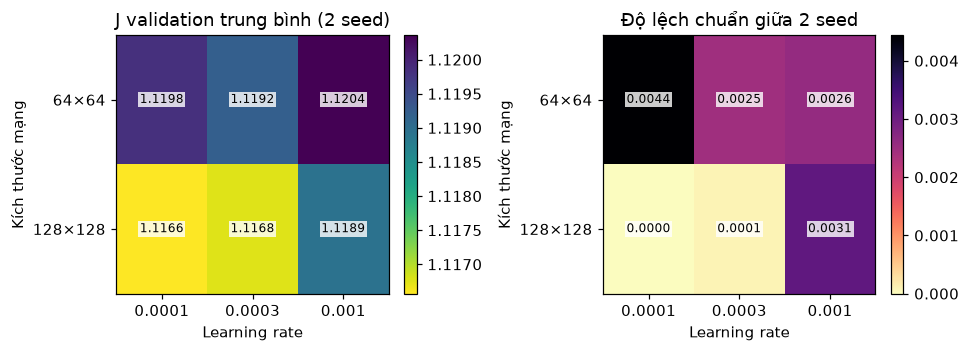

Cấu hình chọn bằng validation: {'name': 'lr0.0001_net128', 'lr': 0.0001, 'width': 128}


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, stat, title, cmap in zip(axes,
    ['mean', 'std'],
    ['J validation trung bình (2 seed)', 'Độ lệch chuẩn giữa 2 seed'],
    ['viridis_r', 'magma_r']):
    grid = xep_hang_tuning.pivot(index='width',
        columns='lr',
        values=stat).sort_index().sort_index(axis=1)
    im = ax.imshow(grid.to_numpy(), aspect='auto', cmap=cmap)
    ax.set_xticks(range(len(grid.columns)), [f'{x:g}' for x in grid.columns])
    ax.set_yticks(range(len(grid.index)), [f'{x}×{x}' for x in grid.index])
    ax.set(xlabel='Learning rate', ylabel='Kích thước mạng', title=title)
    for i in range(len(grid.index)):
        for j in range(len(grid.columns)):
            ax.text(j,
                i,
                f'{grid.iloc[i, j]:.4f}',
                ha='center',
                va='center',
                fontsize=8,
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=1))
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(THU_MUC_KET_QUA / 'tuning_truc_quan.png', dpi=160, bbox_inches='tight')
plt.show()
print('Cấu hình chọn bằng validation:', cau_hinh_chon)

**Cách giải thích:** 6 cấu hình × 2 seed = 12 lượt tuning. Sau khi chọn một cấu hình, PPO học lại 5 seed khác; Q-learning cũng giữ đủ 5 seed. Bảng và hình đang nạp log đã lưu, không có nghĩa mô hình đang học lại mỗi lần hiển thị hình. Số `seconds` trong bảng huấn luyện là thời gian ghi ở lần học ban đầu.

## 5. Kết quả trong cấu hình Caltech
Tất cả thuật toán dưới đây dùng cùng 150 kW, cùng giới hạn pod/pha, cùng 53 cổng trong cohort và 83 ngày test. Bảng chính lấy trung bình seed trong từng ngày rồi trung bình ngày. Bảng tỷ lệ gộp giải thích nhu cầu tổng và điện thiếu tổng.

### Đánh giá sau khi khóa cấu hình bằng validation

In [45]:
thu_tu_phuong_phap = ['PPO', 'FIFO', 'EDF', 'LLF', 'Fixed100', 'Q-learning', 'AverageRate', 'Equal']
cac_bang_ket_qua = []
for ten_phuong_phap in ['FIFO', 'EDF', 'LLF', 'Fixed100', 'AverageRate', 'Equal']:
    bang_cham_luot = cham_diem_cac_ngay(cac_tap['test'],
        policy=(lambda quan_sat: np.array([1.0, 0.0], np.float32)) if ten_phuong_phap == 'Fixed100' else None,
        rule=None if ten_phuong_phap == 'Fixed100' else ten_phuong_phap)
    bang_cham_luot['policy'] = ten_phuong_phap
    bang_cham_luot['seed'] = -1
    cac_bang_ket_qua.append(bang_cham_luot)
for seed in CAC_SEED_DANH_GIA:
    mo_hinh = PPO.load(THU_MUC_MODEL / 'final' / cau_hinh_chon['name'] / f'seed{seed}' / 'best_model.zip',
        device='cpu')
    bang_cham_luot = cham_diem_cac_ngay(cac_tap['test'],
        lambda quan_sat,
        model_dang_cham=mo_hinh: model_dang_cham.predict(quan_sat, deterministic=True)[0])
    bang_cham_luot['policy'] = 'PPO'
    bang_cham_luot['seed'] = seed
    cac_bang_ket_qua.append(bang_cham_luot)
    tep_Q = np.load(THU_MUC_MODEL / 'q_new' / f'seed{seed}' / 'best_model.npz')
    bang_Q = {tuple(k): v for k, v in zip(tep_Q['keys'], tep_Q['values'])}
    bang_cham_luot = cham_diem_cac_ngay(cac_tap['test'],
        lambda quan_sat: HANH_DONG_Q[int(np.argmax(bang_Q.get(nen_trang_thai_Q(quan_sat), np.zeros(9))))])
    bang_cham_luot['policy'] = 'Q-learning'
    bang_cham_luot['seed'] = seed
    cac_bang_ket_qua.append(bang_cham_luot)
    print('Đã chấm PPO và Q-learning seed', seed, flush=True)
ket_qua_tung_ngay = pd.concat(cac_bang_ket_qua, ignore_index=True)
assert ket_qua_tung_ngay.overload_kwh.max() < 1e-07 and ket_qua_tung_ngay.network_peak_ratio.max() <= 1 + 1e-07
ket_qua_tung_ngay.to_csv(THU_MUC_KET_QUA / 'ket_qua_tung_ngay_seed.csv', index=False)
cot_so = [c for c in ket_qua_tung_ngay.select_dtypes('number').columns if c != 'seed']
ket_qua_trung_binh_ngay = ket_qua_tung_ngay.groupby(['policy', 'date'])[cot_so].mean().reset_index()
bang_tong_hop = ket_qua_trung_binh_ngay.groupby('policy')[cot_so].mean().loc[thu_tu_phuong_phap]
bang_tong_hop.to_csv(THU_MUC_KET_QUA / 'tong_hop.csv')
hien_bang(bang_tong_hop[['energy_service_pct', 'unmet_kwh', 'unmet_pct', 'wait_min', 'delay_min', 'smooth_kW2h', 'objective']].round(3),
    'B13. Kết quả chính trên test',
    'F02–F09')

Đã chấm PPO và Q-learning seed 42


Đã chấm PPO và Q-learning seed 43


Đã chấm PPO và Q-learning seed 44


Đã chấm PPO và Q-learning seed 45


Đã chấm PPO và Q-learning seed 46


**B13. Kết quả chính trên test** — tra: `F02–F09`

,Phục vụ điện (%),Thiếu (kWh),Thiếu (% nhu cầu ngày),Chờ ban đầu (phút),Chậm tương đương (phút),∫P²dt (kW²h),J
Phương pháp,,,,,,,
PPO,73.716,131.871,26.284,1.974,17.129,17191.801,1.214
FIFO,72.287,139.421,27.713,4.723,13.233,16654.969,1.261
EDF,73.246,134.489,26.754,1.987,13.816,16952.881,1.205
LLF,73.715,131.878,26.285,2.122,17.099,17190.475,1.215
Fixed100,73.721,131.879,26.279,1.753,18.170,17227.960,1.220
Q-learning,73.661,132.273,26.339,1.740,19.995,17146.812,1.238
AverageRate,70.072,149.831,29.928,0.000,99.031,13688.231,2.025
Equal,72.709,137.260,27.291,0.000,14.644,16809.410,1.217


In [46]:
nhan_xet(f"{bang_tong_hop.objective.idxmin()} có J TB thấp nhất; PPO đạt {bang_tong_hop.loc['PPO','objective']:.4f}. Chưa kết luận hơn/kém rõ khi chưa xem khoảng tin cậy; thiếu điện và chờ/chậm có thể đánh đổi.")

**Nhận xét:** EDF có J TB thấp nhất; PPO đạt 1.2137. Chưa kết luận hơn/kém rõ khi chưa xem khoảng tin cậy; thiếu điện và chờ/chậm có thể đánh đổi.

In [47]:
print('Cùng150 kW và cùng bộ bảo vệ pod/pha. Số chính là trung bình ngày, sau trung bình seed trong ngày.')
print('∫P²dt thấp cũng có thể vì cấp ít điện; phải đọc cùng điện thiếu. J thấp hơn tốt hơn trong cùng cấu hình.')
print('Xếp theo J: ' + ', '.join(bang_tong_hop.objective.sort_values().index))

Cùng150 kW và cùng bộ bảo vệ pod/pha. Số chính là trung bình ngày, sau trung bình seed trong ngày.
∫P²dt thấp cũng có thể vì cấp ít điện; phải đọc cùng điện thiếu. J thấp hơn tốt hơn trong cùng cấu hình.
Xếp theo J: EDF, PPO, LLF, Equal, Fixed100, Q-learning, FIFO, AverageRate


### Bảng chính bằng tiếng Việt và cách đọc số
Giữ các thước đo có ý nghĩa riêng; không cộng hạng của nhiều cột tương quan để tạo ra một “quán quân” khác. J đã là cách gộp ưu tiên mà nhóm đặt trước. Các cột bên dưới đều là trung bình theo ngày, sau khi trung bình seed trong ngày đối với RL.

In [48]:
giai_thich_so("PPO", "objective")

F09 | objective — J
Công thức: 4×thiếu/yêu_cầu + 0,5×chờ/60 + 0,5×chậm/60 + 0,1×tải_bình_phương_chuẩn
Tìm code (Ctrl+F): tinh_thanh_phan_J()
Cách đọc: J thấp hơn tốt hơn; đọc cả bốn thành phần 

PPO | 83 ngày | seed=mọi seed hiện có
Giá trị objective = 1.213720121
  Điện thiếu: 1.051347344
  Chờ: 0.016448104
  Chậm tương đương: 0.142741006
  Tập trung tải: 0.003183667
  Cộng bốn phần = 1.213720121


### Đọc các tỷ lệ cho đúng

In [49]:
ty_le_gop = []
for ten_phuong_phap, nhom_ngay in ket_qua_trung_binh_ngay.groupby('policy'):
    ty_le_gop.append(dict(policy=ten_phuong_phap, requested_kwh=nhom_ngay.requested_kwh.sum(), unmet_kwh=nhom_ngay.unmet_kwh.sum(), pooled_unmet_pct=100 * nhom_ngay.unmet_kwh.sum() / nhom_ngay.requested_kwh.sum(), pooled_wait_min=np.average(nhom_ngay.wait_min, weights=nhom_ngay.sessions), pooled_delay_min=np.average(nhom_ngay.delay_min, weights=nhom_ngay.sessions), mean_daily_unmet_pct=nhom_ngay.unmet_pct.mean(), mean_daily_wait_min=nhom_ngay.wait_min.mean()))
ty_le_gop = pd.DataFrame(ty_le_gop).set_index('policy').loc[thu_tu_phuong_phap]
ty_le_gop.to_csv(THU_MUC_KET_QUA / 'ty_le_gop.csv')
hien_bang(ty_le_gop.round(3), 'B14. Tỷ lệ trên tổng điện và TB ngày', 'F03')

**B14. Tỷ lệ trên tổng điện và TB ngày** — tra: `F03`

,Yêu cầu (kWh),Thiếu (kWh),Thiếu trên tổng kWh (%),Chờ gộp theo xe (phút),Chậm gộp theo xe (phút),Thiếu TB ngày (%),Chờ TB ngày (phút)
Phương pháp,,,,,,,
PPO,41048.54,10945.324,26.664,2.173,18.261,26.284,1.974
FIFO,41048.54,11571.966,28.191,5.128,14.007,27.713,4.723
EDF,41048.54,11162.592,27.194,2.210,14.647,26.754,1.987
LLF,41048.54,10945.858,26.666,2.334,18.232,26.285,2.122
Fixed100,41048.54,10945.944,26.666,1.900,19.375,26.279,1.753
Q-learning,41048.54,10978.688,26.746,1.888,21.445,26.339,1.740
AverageRate,41048.54,12436.003,30.296,0.000,102.109,29.928,0.000
Equal,41048.54,11392.590,27.754,0.000,15.564,27.291,0.000


In [50]:
nhan_xet(f"PPO thiếu {ty_le_gop.loc['PPO','pooled_unmet_pct']:.2f}% trên tổng kWh nhưng {ty_le_gop.loc['PPO','mean_daily_unmet_pct']:.2f}% khi TB tỷ lệ ngày. Hai cách khác trọng số, không phải lỗi tính.")

**Nhận xét:** PPO thiếu 26.66% trên tổng kWh nhưng 26.28% khi TB tỷ lệ ngày. Hai cách khác trọng số, không phải lỗi tính.

In [51]:
hien_bang(bang_tong_hop[['allocation_pct', 'station_utilization_pct', 'session_service_pct', 'never_started_pct']].round(3),
    'B15. Phân bổ, sử dụng trần và đủ điện',
    'F11–F14')

**B15. Phân bổ, sử dụng trần và đủ điện** — tra: `F11–F14`

,Tỷ lệ phân bổ (%),Mức dùng trần trạm (%),Phiên đủ điện (%),Chưa được cấp lần nào (%)
Phương pháp,,,,
PPO,91.796,18.649,53.497,0.072
FIFO,93.743,18.264,53.203,1.695
EDF,93.449,18.517,54.313,0.042
LLF,91.813,18.649,53.452,0.072
Fixed100,91.219,18.649,53.567,0.107
Q-learning,90.176,18.630,53.185,0.046
AverageRate,56.679,17.722,40.948,0.000
Equal,92.908,18.375,52.667,0.000


In [52]:
nhan_xet("Phân bổ so với khả năng nhận điện tức thời; dùng trần so với 150 kW; phiên đủ điện đếm từng xe. Ba mẫu số khác nhau, không gọi chung là hiệu suất.")

**Nhận xét:** Phân bổ so với khả năng nhận điện tức thời; dùng trần so với 150 kW; phiên đủ điện đếm từng xe. Ba mẫu số khác nhau, không gọi chung là hiệu suất.

In [53]:
print('Dùng trần = tổng P / (150 × số slot có xe trong cửa sổ phục vụ). Tỷ lệ phân bổ so với tổng nhu cầu công suất tức thời, chưa áp giới hạn mạng.')
kiem_tra_dong = ket_qua_tung_ngay.groupby('policy')[['network_peak_ratio', 'pod_peak_ratio', 'phase_peak_ratio']].max().loc[thu_tu_phuong_phap]
kiem_tra_dong['clip_steps_pct_mean'] = bang_tong_hop.network_clip_pct
kiem_tra_dong.to_csv(THU_MUC_KET_QUA / 'kiem_tra_gioi_han_test.csv')
hien_bang(kiem_tra_dong.round(6), 'B16. Kiểm tra giới hạn ở mức lớn nhất', 'F15, F18')

Dùng trần = tổng P / (150 × số slot có xe trong cửa sổ phục vụ). Tỷ lệ phân bổ so với tổng nhu cầu công suất tức thời, chưa áp giới hạn mạng.


**B16. Kiểm tra giới hạn ở mức lớn nhất** — tra: `F15, F18`

,Dòng/giới hạn lớn nhất,Tỷ số dòng lớn nhất: pod,Tỷ số dòng lớn nhất: pha,Bước chiếu giảm: TB ngày (%)
Phương pháp,,,,
PPO,1.0,1.0,0.998,0.000
FIFO,1.0,1.0,0.998,0.000
EDF,1.0,1.0,0.998,0.000
LLF,1.0,1.0,0.998,0.000
Fixed100,1.0,1.0,0.998,0.000
Q-learning,1.0,1.0,1.000,0.029
AverageRate,1.0,1.0,0.884,14.416
Equal,1.0,1.0,0.998,0.000


In [54]:
nhan_xet(f"Tỷ số dòng lớn nhất là {kiem_tra_dong.network_peak_ratio.max():.6f}; <=1 trong dung sai là đạt. Clip=0 không nghĩa hết nghẽn vì bộ phân bổ đã giới hạn pod từ trước.")

**Nhận xét:** Tỷ số dòng lớn nhất là 1.000000; <=1 trong dung sai là đạt. Clip=0 không nghĩa hết nghẽn vì bộ phân bổ đã giới hạn pod từ trước.

In [55]:
print('Các tỷ số dòng/giới hạn ở trên là mức LỚN NHẤT qua ngày và seed, không phải trung bình.')
dong_PPO = ty_le_gop.loc['PPO']
print(f'Trên toàn test: thiếu {dong_PPO.unmet_kwh:.2f} / yêu cầu {dong_PPO.requested_kwh:.2f} kWh = {dong_PPO.pooled_unmet_pct:.2f}%.')
print(f'Lấy trung bình tỷ lệ riêng từng ngày cho {dong_PPO.mean_daily_unmet_pct:.2f}%; hai cách có trọng số khác nhau.')
thanh_phan_J = pd.DataFrame({'Điện thiếu': TRONG_SO_J['dien_thieu'] * bang_tong_hop.unmet_pct / 100, 'Chờ': TRONG_SO_J['cho'] * bang_tong_hop.wait_min / 60, 'Chậm tương đương': TRONG_SO_J['cham'] * bang_tong_hop.delay_min / 60, 'Tập trung tải': TRONG_SO_J['tap_trung_tai'] * bang_tong_hop.smooth_normalized})
assert np.allclose(thanh_phan_J.sum(axis=1), bang_tong_hop.objective)
thanh_phan_J.to_csv(THU_MUC_KET_QUA / 'thanh_phan_reward.csv')
hien_bang(thanh_phan_J.round(4), 'B17. Bốn thành phần của J', 'F09')

Các tỷ số dòng/giới hạn ở trên là mức LỚN NHẤT qua ngày và seed, không phải trung bình.
Trên toàn test: thiếu 10945.32 / yêu cầu 41048.54 kWh = 26.66%.
Lấy trung bình tỷ lệ riêng từng ngày cho 26.28%; hai cách có trọng số khác nhau.


**B17. Bốn thành phần của J** — tra: `F09`

,Điện thiếu,Chờ,Chậm tương đương,Tập trung tải
Phương pháp,,,,
PPO,1.051,0.016,0.143,0.003
FIFO,1.108,0.039,0.110,0.003
EDF,1.070,0.017,0.115,0.003
LLF,1.051,0.018,0.142,0.003
Fixed100,1.051,0.015,0.151,0.003
Q-learning,1.054,0.014,0.167,0.003
AverageRate,1.197,0.000,0.825,0.002
Equal,1.092,0.000,0.122,0.003


In [56]:
nhan_xet(f"Ở PPO, tải bình phương chiếm {100*thanh_phan_J.loc['PPO','Tập trung tải']/bang_tong_hop.loc['PPO','objective']:.3f}% J, nên đây là mục tiêu phụ. Bốn cột cộng lại đúng J, không đổi trọng số sau khi xem test.")

**Nhận xét:** Ở PPO, tải bình phương chiếm 0.262% J, nên đây là mục tiêu phụ. Bốn cột cộng lại đúng J, không đổi trọng số sau khi xem test.

### Biểu đồ đa tiêu chí

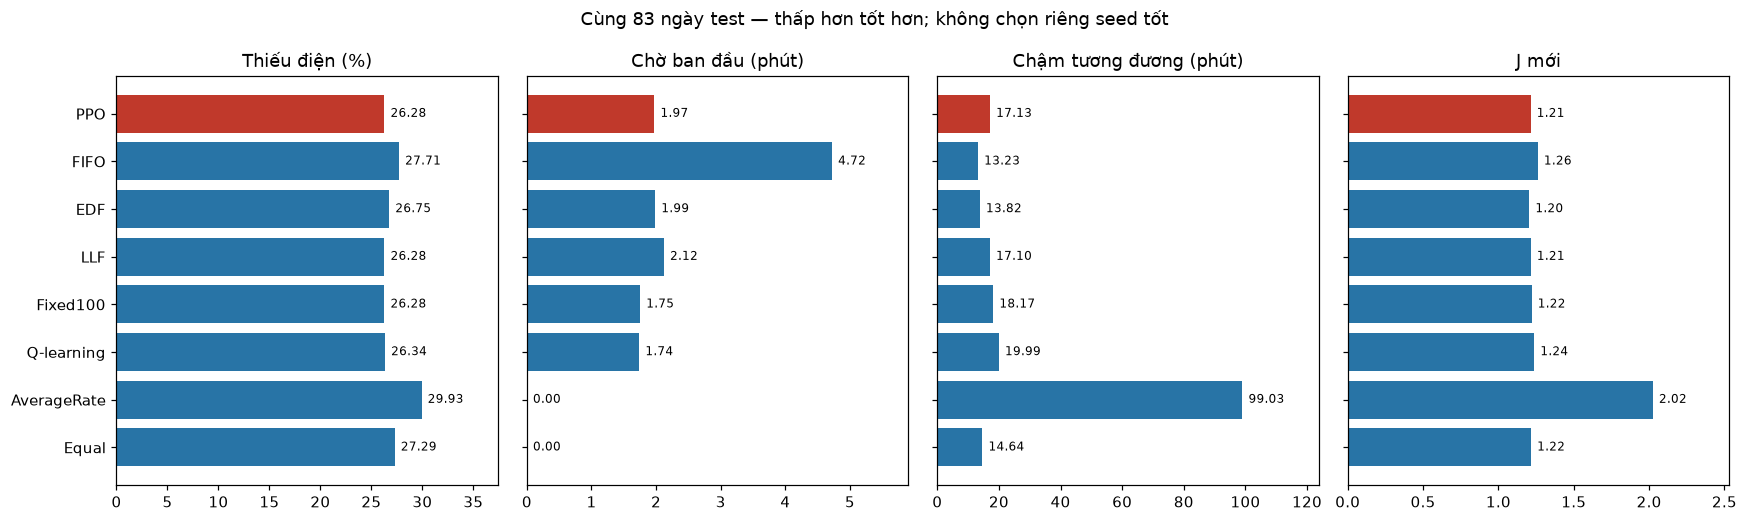

In [57]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.8), sharey=True)
colors = ['#c0392b'] + ['#2874a6'] * 7
for ax, col, title in zip(axes,
    ['unmet_pct', 'wait_min', 'delay_min', 'objective'],
    ['Thiếu điện (%)', 'Chờ ban đầu (phút)', 'Chậm tương đương (phút)', 'J mới']):
    values = bang_tong_hop[col]
    ax.barh(thu_tu_phuong_phap, values, color=colors)
    ax.set_title(title)
    ax.set_xlim(0, values.max() * 1.25)
    for i, v in enumerate(values):
        ax.text(v + values.max() * 0.02, i, f'{v:.2f}', va='center', fontsize=8)
axes[0].invert_yaxis()
fig.suptitle('Cùng 83 ngày test — thấp hơn tốt hơn; không chọn riêng seed tốt')
fig.tight_layout()
fig.savefig(THU_MUC_KET_QUA / 'so_sanh_moi.png', dpi=180, bbox_inches='tight')
plt.show()

**Giải thích sau cell:** Thanh ngắn hơn tốt hơn. Hạ tầng đã đổi nên không so thẳng điểm J với notebook 45 kW.

### Độ ổn định và đường học thật

In [58]:
ket_qua_tung_seed = ket_qua_tung_ngay[ket_qua_tung_ngay.seed >= 0].groupby(['policy', 'seed'])[cot_so].mean().reset_index()
ket_qua_tung_seed.to_csv(THU_MUC_KET_QUA / 'tung_seed.csv', index=False)
hien_bang(ket_qua_tung_seed[['policy', 'seed', 'objective', 'unmet_pct', 'wait_min', 'delay_min']].round(4),
    'B18. Kết quả từng seed',
    'T01, F09')

**B18. Kết quả từng seed** — tra: `T01, F09`

,Phương pháp,Seed,J,Thiếu (% nhu cầu ngày),Chờ ban đầu (phút),Chậm tương đương (phút)
0,PPO,42,1.214,26.285,1.975,17.136
1,PPO,43,1.213,26.284,1.969,17.098
2,PPO,44,1.214,26.282,1.978,17.186
3,PPO,45,1.213,26.284,1.969,17.098
4,PPO,46,1.214,26.284,1.978,17.128
5,Q-learning,42,1.238,26.357,1.771,19.950
6,Q-learning,43,1.238,26.349,1.732,19.960
7,Q-learning,44,1.243,26.331,1.669,20.736
8,Q-learning,45,1.240,26.340,1.893,20.062
9,Q-learning,46,1.230,26.320,1.634,19.265


In [59]:
nhan_xet("Mỗi hàng chấm trên cùng 83 ngày; giữ cả seed tốt và kém. So dao động giữa các hàng PPO để xét ổn định, không chọn một seed đẹp để đại diện cả phương pháp.")

**Nhận xét:** Mỗi hàng chấm trên cùng 83 ngày; giữ cả seed tốt và kém. So dao động giữa các hàng PPO để xét ổn định, không chọn một seed đẹp để đại diện cả phương pháp.

In [60]:
do_on_dinh = ket_qua_tung_seed.groupby('policy')[['objective', 'unmet_pct', 'wait_min', 'delay_min']].agg(['mean', 'std'])
hien_bang(do_on_dinh.round(4), 'B19. Trung bình và độ lệch chuẩn giữa seed', 'T01')

**B19. Trung bình và độ lệch chuẩn giữa seed** — tra: `T01`

,J — Trung bình,J — Độ lệch chuẩn,Thiếu (% nhu cầu ngày) — Trung bình,Thiếu (% nhu cầu ngày) — Độ lệch chuẩn,Chờ ban đầu (phút) — Trung bình,Chờ ban đầu (phút) — Độ lệch chuẩn,Chậm tương đương (phút) — Trung bình,Chậm tương đương (phút) — Độ lệch chuẩn
Phương pháp,,,,,,,,
PPO,1.214,0.000,26.284,0.001,1.974,0.004,17.129,0.036
Q-learning,1.238,0.005,26.340,0.014,1.740,0.101,19.994,0.522


In [61]:
nhan_xet(f"PPO có độ lệch chuẩn J {do_on_dinh.loc['PPO',('objective','std')]:.6f} giữa 5 seed. Đây là độ lệch chuẩn mẫu, không phải CI hay bảo đảm ổn định trên trạm khác.")

**Nhận xét:** PPO có độ lệch chuẩn J 0.000310 giữa 5 seed. Đây là độ lệch chuẩn mẫu, không phải CI hay bảo đảm ổn định trên trạm khác.

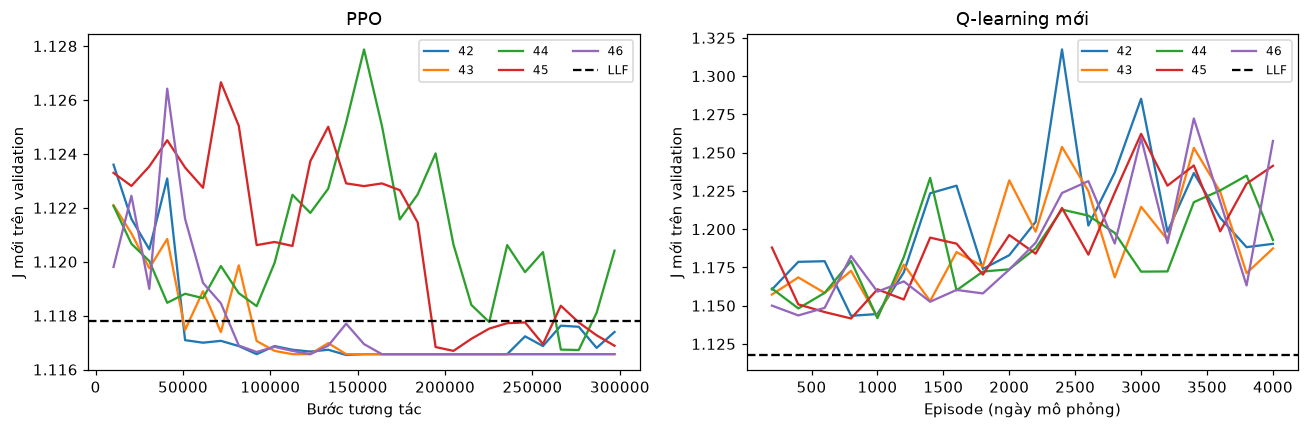

**B20. Chẩn đoán Q-learning** — tra: `T02`

,Seed,Episode tốt nhất,J val tốt nhất,J val cuối
0,42,800,1.143,1.190
1,43,1000,1.143,1.187
2,44,1000,1.142,1.193
3,45,800,1.142,1.241
4,46,400,1.144,1.258


In [62]:
do_on_dinh.to_csv(THU_MUC_KET_QUA / 'on_dinh_seed.csv')
curves = []
chan_doan_Q = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
llf_val = float(cham_diem_cac_ngay(cac_tap['val'], rule='LLF').objective.mean())
for seed in CAC_SEED_DANH_GIA:
    tep_log = np.load(THU_MUC_MODEL / 'final' / cau_hinh_chon['name'] / f'seed{seed}' / 'evaluations.npz')
    J_validation = -tep_log['results'].mean(axis=1)
    buoc_hoc = tep_log['timesteps']
    axes[0].plot(buoc_hoc, J_validation, label=str(seed))
    curves.extend((dict(seed=seed, steps=int(t), val_objective=float(v)) for t, v in zip(buoc_hoc, J_validation)))
    log_Q = pd.read_csv(THU_MUC_MODEL / 'q_new' / f'seed{seed}' / 'learning.csv')
    axes[1].plot(log_Q.episode, log_Q.val_objective, label=str(seed))
    chan_doan_Q.append(dict(seed=seed, best_episode=int(log_Q.loc[log_Q.val_objective.idxmin(), 'episode']), best_val_J=float(log_Q.val_objective.min()), last_val_J=float(log_Q.val_objective.iloc[-1])))
for ax, title, xlabel in zip(axes,
    ['PPO', 'Q-learning mới'],
    ['Bước tương tác', 'Episode (ngày mô phỏng)']):
    ax.axhline(llf_val, ls='--', color='black', label='LLF')
    ax.set(title=title, xlabel=xlabel, ylabel='J mới trên validation')
    ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
fig.savefig(THU_MUC_KET_QUA / 'duong_hoc_moi.png', dpi=180, bbox_inches='tight')
plt.show()
duong_hoc = pd.DataFrame(curves)
duong_hoc.to_csv(THU_MUC_KET_QUA / 'ppo_validation.csv', index=False)
chan_doan_Q = pd.DataFrame(chan_doan_Q)
chan_doan_Q.to_csv(THU_MUC_KET_QUA / 'q_dien_bien.csv', index=False)
hien_bang(chan_doan_Q.round(4), 'B20. Chẩn đoán Q-learning', 'T02')

In [63]:
nhan_xet(f"{int((chan_doan_Q.best_episode<SO_EPISODE_Q).sum())}/{len(chan_doan_Q)} seed tốt nhất trước episode cuối; học thêm không mặc nhiên tốt hơn. Khi chấm đã nạp checkpoint validation tốt nhất, không lấy bảng Q cuối.")

**Nhận xét:** 5/5 seed tốt nhất trước episode cuối; học thêm không mặc nhiên tốt hơn. Khi chấm đã nạp checkpoint validation tốt nhất, không lấy bảng Q cuối.

In [64]:
print(f'Q-learning: {(chan_doan_Q.best_episode < SO_EPISODE_Q).sum()}/{len(chan_doan_Q)} seed tốt nhất trước mốc cuối; học thêm chưa chắc tốt hơn. Chưa khẳng định hội tụ.')
print('Trục ngang là bước tương tác, không phải ngày lịch; 38 là số ngày validation. Đường giảm chưa đủ để khẳng định hội tụ.')

Q-learning: 5/5 seed tốt nhất trước mốc cuối; học thêm chưa chắc tốt hơn. Chưa khẳng định hội tụ.
Trục ngang là bước tương tác, không phải ngày lịch; 38 là số ngày validation. Đường giảm chưa đủ để khẳng định hội tụ.


### Khoảng tin cậy ghép cặp cùng ngày, resample theo tuần và seed

In [65]:
def khoang_tin_cay_chenh_lech(reference, column, repeats=2000):
    """F19: bootstrap có hoàn lại theo TUẦN và SEED; giữ số lần tuần được lấy lặp."""
    bang_PPO = ket_qua_tung_ngay[ket_qua_tung_ngay.policy == 'PPO']
    bang_doi_chung = ket_qua_tung_ngay[ket_qua_tung_ngay.policy == reference]
    cac_ngay = sorted(bang_PPO.date.unique())
    ma_tuan = pd.to_datetime(cac_ngay).to_period('W').factorize()[0]
    ma_tran_PPO = bang_PPO.pivot(index='seed',
        columns='date',
        values=column).reindex(columns=cac_ngay).to_numpy()
    ma_tran_doi_chung = bang_doi_chung.pivot(index='seed',
        columns='date',
        values=column).reindex(columns=cac_ngay).to_numpy()
    bo_ngau_nhien = np.random.default_rng(20261027)
    cac_chenh_lech = []
    cac_tuan = np.unique(ma_tuan)
    for _ in range(repeats):
        tuan_lay_lap = bo_ngau_nhien.choice(cac_tuan, len(cac_tuan), replace=True)
        chi_so_ngay = np.concatenate([np.where(ma_tuan == k)[0] for k in tuan_lay_lap])
        seed_PPO = bo_ngau_nhien.integers(len(ma_tran_PPO), size=len(ma_tran_PPO))
        seed_doi_chung = bo_ngau_nhien.integers(len(ma_tran_doi_chung), size=len(ma_tran_doi_chung))
        cac_chenh_lech.append(ma_tran_PPO[seed_PPO][:, chi_so_ngay].mean() - ma_tran_doi_chung[seed_doi_chung][:, chi_so_ngay].mean())
    can_duoi, can_tren = np.quantile(cac_chenh_lech, [0.025, 0.975])
    return dict(reference=reference,
        metric=column,
        delta=float(ma_tran_PPO.mean() - ma_tran_doi_chung.mean()),
        low=float(can_duoi),
        high=float(can_tren))
khoang_tin_cay = pd.DataFrame([khoang_tin_cay_chenh_lech(ref, col) for ref in ['FIFO', 'EDF', 'LLF', 'Fixed100', 'Equal', 'AverageRate'] for col in ['objective', 'unmet_pct', 'wait_min', 'delay_min']])
khoang_tin_cay['unit'] = khoang_tin_cay.metric.map({'objective': 'điểm J', 'unmet_pct': 'điểm phần trăm', 'wait_min': 'phút', 'delay_min': 'phút'})
khoang_tin_cay.to_csv(THU_MUC_KET_QUA / 'khoang_tin_cay.csv', index=False)
hien_bang(khoang_tin_cay.round(4), 'B21. Chênh lệch PPO với đối chứng', 'F19')

**B21. Chênh lệch PPO với đối chứng** — tra: `F19`

,Đối chứng,Chỉ số,Chênh lệch PPO−đối chứng,Cận dưới 95%,Cận trên 95%,Đơn vị
0,FIFO,objective,-0.048,-0.058,-0.036,điểm J
1,FIFO,unmet_pct,-1.429,-1.780,-1.105,điểm phần trăm
2,FIFO,wait_min,-2.750,-3.555,-2.046,phút
3,FIFO,delay_min,3.896,2.667,5.392,phút
4,EDF,objective,0.009,-0.000,0.019,điểm J
5,EDF,unmet_pct,-0.470,-0.684,-0.277,điểm phần trăm
6,EDF,wait_min,-0.013,-0.774,0.795,phút
7,EDF,delay_min,3.313,2.137,4.767,phút
8,LLF,objective,-0.001,-0.002,0.000,điểm J
9,LLF,unmet_pct,-0.001,-0.004,0.001,điểm phần trăm


In [66]:
nhan_xet("Δ âm nghĩa là PPO thấp hơn; CI chứa 0 nghĩa chưa rõ khác biệt. Các CI này mang tính thăm dò và chưa hiệu chỉnh nhiều phép so sánh.")

**Nhận xét:** Δ âm nghĩa là PPO thấp hơn; CI chứa 0 nghĩa chưa rõ khác biệt. Các CI này mang tính thăm dò và chưa hiệu chỉnh nhiều phép so sánh.

In [67]:
print('Δ = PPO − đối chứng; âm có lợi. Khoảng chứa 0 chưa đủ chứng cứ khác biệt. Đây là CI mô tả, chưa hiệu chỉnh nhiều phép so sánh.')

Δ = PPO − đối chứng; âm có lợi. Khoảng chứa 0 chưa đủ chứng cứ khác biệt. Đây là CI mô tả, chưa hiệu chỉnh nhiều phép so sánh.


### Một ngày chọn theo nhu cầu trung vị, trước khi nhìn thắng thua

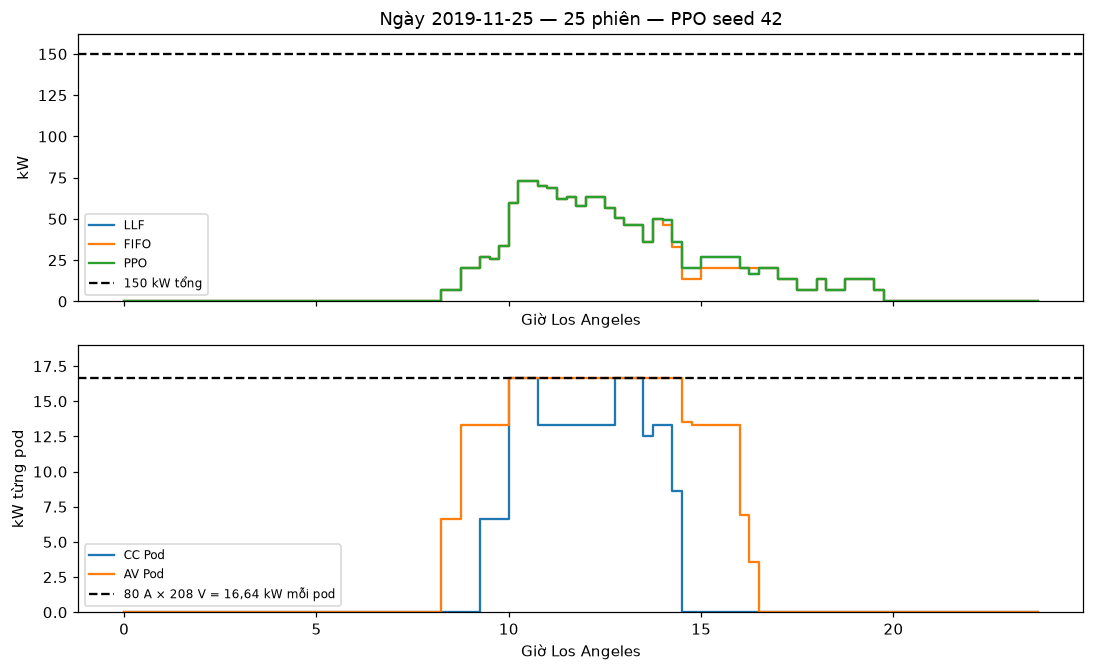

**B22. Một số xe trong ngày minh họa** — tra: `F01–F05`

,sessionID,Đến (giờ),Dừng phục vụ (giờ),Yêu cầu (kWh),Đã cấp (kWh),Thiếu (kWh),Chờ (phút),Chậm tương đương (phút)
15,2_39_79_379_2019-11-25 16:02:02.092538,8.25,15.25,37.5,37.50,0.00,0.0,51.96
5,2_39_139_28_2019-11-25 16:41:57.046937,8.75,12.00,6.5,6.50,0.00,0.0,1.41
14,2_39_79_378_2019-11-25 16:44:47.574022,8.75,19.00,24.0,24.00,0.00,0.0,248.65
8,2_39_78_361_2019-11-25 17:07:01.266135,9.25,18.25,28.0,28.00,0.00,0.0,17.60
2,2_39_126_20_2019-11-25 17:42:08.666387,9.75,13.50,20.0,20.00,0.00,0.0,14.71
3,2_39_129_17_2019-11-25 17:30:09.897883,9.75,10.50,9.0,4.99,4.01,0.0,0.00
0,2_39_124_22_2019-11-25 17:47:26.357249,10.00,11.25,8.0,8.00,0.00,0.0,2.88
11,2_39_78_366_2019-11-25 17:45:37.383964,10.00,10.75,32.0,4.99,27.01,0.0,0.00


In [68]:
requests = np.array([d['req'].sum() for d in cac_tap['test']])
ngay_minh_hoa = cac_tap['test'][int(np.argmin(abs(requests - np.median(requests))))]
mo_hinh = PPO.load(THU_MUC_MODEL / 'final' / cau_hinh_chon['name'] / f'seed{CAC_SEED_DANH_GIA[0]}' / 'best_model.zip',
    device='cpu')
tai_mot_ngay = {'hour': ngay_minh_hoa['hours']}
fig, (ax, podax) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)
for ten_duong in ['LLF', 'FIFO', 'PPO']:
    so_chi_tiet = mo_phong_cac_ngay([ngay_minh_hoa],
        policy=(lambda o: mo_hinh.predict(o, deterministic=True)[0]) if ten_duong == 'PPO' else None,
        rule=None if ten_duong == 'PPO' else ten_duong)[0]
    tai_mot_ngay[ten_duong] = so_chi_tiet['P']
    ax.step(ngay_minh_hoa['hours'], so_chi_tiet['P'], where='post', label=ten_duong)
ax.axhline(TRAN_TRAM_KW, color='black', ls='--', label='150 kW tổng')
ax.set(title=f"Ngày {ngay_minh_hoa['date']} — {ngay_minh_hoa['n']} phiên — PPO seed {CAC_SEED_DANH_GIA[0]}",
    xlabel='Giờ Los Angeles',
    ylabel='kW',
    ylim=(0, TRAN_TRAM_KW * 1.08))
ax.legend(fontsize=8)
moi_truong_truy_vet = MoiTruongSac([ngay_minh_hoa])
quan_sat, _ = moi_truong_truy_vet.reset(options={'day_idx': 0})
het_ngay = False
pod_trace = np.zeros((2, ngay_minh_hoa['T']))
while not het_ngay:
    dien_truoc_buoc = moi_truong_truy_vet.dien_con_lai.copy()
    quan_sat, _, het_ngay, _, _ = moi_truong_truy_vet.step(mo_hinh.predict(quan_sat, deterministic=True)[0])
    pod_trace[:,
        moi_truong_truy_vet.buoc - 1] = ngay_minh_hoa['pods'] @ ((dien_truoc_buoc - moi_truong_truy_vet.dien_con_lai) / BUOC_GIO)
assert np.allclose(moi_truong_truy_vet.tai_kw, tai_mot_ngay['PPO'])
for chi_so_pod, ten_duong in enumerate(['CC Pod', 'AV Pod']):
    tai_mot_ngay[ten_duong] = pod_trace[chi_so_pod]
    podax.step(ngay_minh_hoa['hours'], pod_trace[chi_so_pod], where='post', label=ten_duong)
podax.axhline(DIEN_AP_V * 80 / 1000, ls='--', color='black', label='80 A × 208 V = 16,64 kW mỗi pod')
podax.set(xlabel='Giờ Los Angeles', ylabel='kW từng pod', ylim=(0, 19))
podax.legend(fontsize=8)
moi_truong_truy_vet.close()
fig.tight_layout()
fig.savefig(THU_MUC_KET_QUA / 'mot_ngay_moi.png', dpi=180, bbox_inches='tight')
plt.show()
pd.DataFrame(tai_mot_ngay).to_csv(THU_MUC_KET_QUA / 'mot_ngay.csv', index=False)
chi_tiet_tung_xe = pd.DataFrame({'sessionID': ngay_minh_hoa['ids'], 'Đến (giờ)': ngay_minh_hoa['arr'] * 0.25, 'Dừng phục vụ (giờ)': ngay_minh_hoa['stop'] * 0.25, 'Yêu cầu (kWh)': ngay_minh_hoa['req'], 'Đã cấp (kWh)': ngay_minh_hoa['req'] - so_chi_tiet['rem'], 'Thiếu (kWh)': so_chi_tiet['rem'], 'Chờ (phút)': so_chi_tiet['wait_min'], 'Chậm tương đương (phút)': so_chi_tiet['delay_min']}).sort_values(['Đến (giờ)', 'sessionID'])
chi_tiet_tung_xe.to_csv(THU_MUC_KET_QUA / 'vi_du_tung_xe.csv', index=False)
hien_bang(chi_tiet_tung_xe.head(8).round(2), 'B22. Một số xe trong ngày minh họa', 'F01–F05')

In [69]:
nhan_xet(f"Bảng chỉ hiện 8/{ngay_minh_hoa['n']} xe; điện thiếu = yêu cầu − đã cấp. Chậm có thể dương dù xe đủ điện và bằng 0 dù xe còn thiếu, theo định nghĩa F05.")

**Nhận xét:** Bảng chỉ hiện 8/25 xe; điện thiếu = yêu cầu − đã cấp. Chậm có thể dương dù xe đủ điện và bằng 0 dù xe còn thiếu, theo định nghĩa F05.

In [70]:
print(f"Hiển thị 8/{ngay_minh_hoa['n']} xe để minh họa. Trung bình trên TẤT CẢ {ngay_minh_hoa['n']} xe ngày này: chờ {so_chi_tiet['wait_min'].mean():.2f} phút; chậm {so_chi_tiet['delay_min'].mean():.2f} phút.")

Hiển thị 8/25 xe để minh họa. Trung bình trên TẤT CẢ 25 xe ngày này: chờ 0.00 phút; chậm 19.97 phút.


## 6. Kết luận và so với bản trước

In [71]:
phien_duoc_chon['unavoidable_kwh'] = tinh_can_thieu_rieng_xe(phien_duoc_chon.request,
    phien_duoc_chon.arr,
    phien_duoc_chon.stop)
phien_test = phien_duoc_chon[phien_duoc_chon.local_date.astype(str).isin({d['date'] for d in cac_tap['test']})]
can_thieu_test_pct = 100 * phien_test.unavoidable_kwh.sum() / phien_test.request.sum()
yeu_cau_so_lich_su = phien_duoc_chon.request.sum() / phien_duoc_chon.kWhDelivered.sum()
dong_PPO = bang_tong_hop.loc['PPO']
quy_tac_J_tot_nhat = bang_tong_hop.loc[['FIFO', 'EDF', 'LLF', 'Fixed100', 'Equal', 'AverageRate'],
    'objective'].idxmin()
dong_tot_nhat = bang_tong_hop.loc[quy_tac_J_tot_nhat]
co_tin_hieu_tot_hon = khoang_tin_cay[(khoang_tin_cay.metric == 'objective') & (khoang_tin_cay.high < 0)].reference.tolist()
co_tin_hieu_kem_hon = khoang_tin_cay[(khoang_tin_cay.metric == 'objective') & (khoang_tin_cay.low > 0)].reference.tolist()
ket_luan = f"Trong cấu hình Caltech {TRAN_TRAM_KW:g} kW có pod/pha, PPO {len(CAC_SEED_DANH_GIA)} seed đạt J={dong_PPO.objective:.4f}, thiếu {dong_PPO.unmet_pct:.2f}% trung bình ngày, chờ {dong_PPO.wait_min:.2f} phút, chậm tương đương {dong_PPO.delay_min:.2f} phút. Mốc không học có J thấp nhất là {quy_tac_J_tot_nhat}: {dong_tot_nhat.objective:.4f}. Bootstrap thăm dò cho tín hiệu PPO tốt hơn theo J: {', '.join(co_tin_hieu_tot_hon) or 'chưa có'}; kém hơn: {', '.join(co_tin_hieu_kem_hon) or 'chưa có'}. Cận thiếu riêng từng xe là {can_thieu_test_pct:.2f}% tổng nhu cầu test. Yêu cầu bằng {yeu_cau_so_lich_su:.2f} lần điện lịch sử được cấp."
print(ket_luan)
(THU_MUC_KET_QUA / 'ket_luan.txt').write_text(ket_luan, encoding='utf-8')
print('Kết quả trước45 kW không so trực tiếp với bảng này: cả trần tổng, giới hạn cổng/pod/pha và quan sát policy đã thay đổi. Không quy thay đổi điện thiếu cho riêng PPO.')
print('Bộ chiếu an toàn khả thi nhưng chưa tối ưu tái phân bổ công suất. PPO chỉ có2 tham số; không thể tái tạo mọi cách chia của Equal. Tuning không bảo đảm thắng heuristic.')
print('Test từng được xem qua; giữ nguyên trọng số và cấu hình sau khi chấm, cần dữ liệu mới để xác nhận độc lập.')

Trong cấu hình Caltech 150 kW có pod/pha, PPO 5 seed đạt J=1.2137, thiếu 26.28% trung bình ngày, chờ 1.97 phút, chậm tương đương 17.13 phút. Mốc không học có J thấp nhất là EDF: 1.2050. Bootstrap thăm dò cho tín hiệu PPO tốt hơn theo J: FIFO, Fixed100, AverageRate; kém hơn: chưa có. Cận thiếu riêng từng xe là 25.66% tổng nhu cầu test. Yêu cầu bằng 1.85 lần điện lịch sử được cấp.
Kết quả trước45 kW không so trực tiếp với bảng này: cả trần tổng, giới hạn cổng/pod/pha và quan sát policy đã thay đổi. Không quy thay đổi điện thiếu cho riêng PPO.
Bộ chiếu an toàn khả thi nhưng chưa tối ưu tái phân bổ công suất. PPO chỉ có2 tham số; không thể tái tạo mọi cách chia của Equal. Tuning không bảo đảm thắng heuristic.
Test từng được xem qua; giữ nguyên trọng số và cấu hình sau khi chấm, cần dữ liệu mới để xác nhận độc lập.


**Giải thích sau cell:** Kết luận được tạo từ số vừa chạy. Tuning không bảo đảm PPO thắng; chiếu an toàn chưa tối ưu cũng có thể hạn chế mọi phương pháp.

**Ba ý để giải thích kết quả:** (1) Hạ tầng có giới hạn cục bộ: tổng chưa chạm 150 kW nhưng một pod đã chạm 16,64 kW. (2) Nhiều yêu cầu vượt điện có thể cấp trong cửa sổ sạc; phần vượt cận riêng từng xe vẫn có thể do giới hạn mạng, không được gọi hết là lỗi thuật toán. (3) PPO chỉ điều khiển hai tham số qua bộ phân bổ nên phạm vi cách chia điện bị giới hạn; kết quả gần LLF không chứng minh LLF tối ưu. Tỷ số yêu cầu/điện lịch sử cao chưa đủ kết luận người dùng khai sai.

## 7. Hạn chế và tài liệu tham khảo
Đã đưa vào: giới hạn cổng 32 A, tổng 150 kW,2 pod 80 A,6 giới hạn dòng sơ/thứ cấp và ánh xạ cổng/pha theo mã nguồn Caltech. Chưa đưa vào: nấc pilot rời rạc, SOC/pin phi tuyến, tổn hao, công suất phản kháng, điện áp biến động và điều khiển trạm thật. Dùng điện áp danh định và mô hình dòng cùng pha với điện áp như cấu hình tham khảo.

Bộ bảo vệ giảm công suất để khả thi nhưng chưa tái phân bổ tối ưu phần bị giảm sang cổng khác. Số “kWh đề xuất bị giảm” là tổng phần can thiệp theo slot; không đồng nhất với điện thiếu cuối phiên, vì cùng xe có thể được đề xuất lại ở slot sau.

Cohort là nhóm phiên có khai báo hợp lệ và kết thúc cùng ngày; trạm thật phục vụ nhiều phiên hơn cohort. Không suy rộng rằng giới hạn 150 kW làm toàn bộ trạm hết cạnh tranh. Test đã được xem trong các vòng trước, cần dữ liệu mới để xác nhận độc lập. Không đổi trọng số hoặc chọn lại công suất sau khi xem test để tạo lợi thế PPO.

**Nghiên cứu liên quan:** ACN-Data [7] cung cấp dữ liệu/EDA; ACN-Sim [8] cung cấp mô hình và FIFO/EDF/LLF, không phải kết quả PPO để nhóm sao chép. Đồ án dùng PPO [9], Q-learning [10] và bộ bảo vệ của nhóm với thông số tham khảo Caltech. Do simulator, cohort và mục tiêu khác, không so trực tiếp điểm J với bài báo khác.

1. Z. J. Lee, *The Adaptive Charging Network Research Portal: Systems, Tools, and Algorithms*, Caltech,2021. [Bảng 3.9, trang 41; Bảng 3.10](https://thesis.caltech.edu/14191/1/Lee_Zachary_J_2021_Thesis.pdf#page=53).
2. ACNPortal v0.3.3, [cấu hình Caltech](https://github.com/zach401/acnportal/blob/v0.3.3/acnportal/acnsim/network/sites/caltech_acn.py), thông số và ánh xạ cổng/pha.
3. ACNPortal v0.3.3, [giới hạn và nấc dòng EVSE](https://github.com/zach401/acnportal/blob/v0.3.3/acnportal/acnsim/models/evse.py).
4. ACNPortal v0.3.3, [tính dòng và kiểm tra khả thi](https://github.com/zach401/acnportal/blob/v0.3.3/acnportal/acnsim/network/charging_network.py).
5. Z. J. Lee et al., *Large-Scale Adaptive Electric Vehicle Charging*,2018. [Hình 2](https://ev.caltech.edu/assets/pub/Large_Scale_Adaptive_Electric_Vehicle_Charging.pdf).
6. U.S. DOE, [Managed Charging Minimizes Costs in NLR’s Parking Garage](https://www.energy.gov/cmei/femp/managed-charging-minimizes-costs-national-laboratory-rockies-parking-garage), trường hợp 108 cổng/460 kW.
7. Z. J. Lee, T. Li, S. H. Low, [ACN-Data](https://ev.caltech.edu/assets/pub/ACN_Data_Analysis_and_Applications.pdf), e-Energy,2019, DOI 10.1145/3307772.3328313.
8. Z. J. Lee et al., [ACN-Sim](https://arxiv.org/html/2012.02809v2).
9. J. Schulman et al., [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347),2017.
10. C. J. C. H. Watkins, P. Dayan, [Q-learning](https://doi.org/10.1007/BF00992698),1992.

**Chạy lại:** notebook tự chứa code. Thư mục `mo_hinh_caltech_150` chứa checkpoint và log của môi trường này; `ket_qua_de_hieu` chứa bảng/hình/kết luận. Khi đổi dữ liệu, tao_ma_tran_gioi_han hoặc reward phải huấn luyện lại. Word giữ bản cũ theo yêu cầu.